# IMF Türkiye: Macro-Financial Intelligence Pipeline — Final Submission

This notebook implements an evidence-grounded workflow for analysing the IMF *Republic of Türkiye: 2025 Article IV Consultation* report. It combines PDF processing, token-aware chunking, LLM-based extraction and evaluation, local dense-vector retrieval, and executive visual analytics.

**Student ID:** 24142515  
**Source:** IMF Country Report No. 26/043  
**Environment:** Google Colab / Python

The workflow preserves source pages, quotations, indicator definitions, units, reference periods and scenario status so that extracted findings can be checked against the original report.

<div style="padding:26px 28px;border-radius:14px;background:linear-gradient(120deg,#10243a,#1e5268);color:white;">
<h1 style="margin:0;color:white;font-size:30px;">IMF Türkiye | Macro-Financial Intelligence Pipeline</h1>
<p style="font-size:15px;margin:10px 0 0 0;color:#e7f0f5;">Evidence-grounded extraction • Local dense-vector RAG • Model benchmarking • Executive analytics</p>
<p style="font-size:12px;margin:18px 0 0 0;color:#d4e2e9;">INDIVIDUAL DATA SCIENCE ASSIGNMENT | STUDENT 24142515</p>
</div>

**Country:** Türkiye  
**Source:** IMF Country Report No. 26/043 — *Republic of Türkiye: 2025 Article IV Consultation*  
**Report period:** 2025–2026  
**Implementation:** Google Colab / Python, local PDF processing, Gemini API, FastEmbed and FAISS

### Project objective
Build a reproducible PDF-to-dashboard pipeline that converts an IMF country report into traceable macro-financial evidence, thematic indicators, qualitative risk insights, grounded retrieval responses and executive visualisations.

### Pipeline at a glance
`IMF PDF → extraction & cleaning → token-aware chunks → LLM extraction → evidence audit → local vector index → RAG evaluation → dashboard & export`

**Evidence principle:** no value is interpolated or invented. Every extracted numerical observation should retain its definition, period, status, PDF page and source quotation. Missing or conflicting values remain visible for human review.

**Execution:** run cells from top to bottom in Google Colab. API calls are cached and long extraction loops save progress after each completed bundle.

### 0A. Install dependencies (run once per fresh Colab runtime)

In [1]:
# Install project dependencies in the active Colab Python environment.
import sys
import subprocess

packages = [
    "pypdf",
    "seaborn",
    "scikit-learn",
    "requests",
    "google-genai",
    "fastembed",
    "tiktoken",
    "pydantic"
]

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", *packages
])

# FAISS is optional: the notebook has a scikit-learn fallback if installation fails.
try:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "faiss-cpu"
    ])
    print("FAISS installed.")
except Exception as exc:
    print("FAISS could not be installed; scikit-learn fallback will be used.")
    print("Reason:", str(exc)[:300])

print("Dependency installation finished. Continue to the Drive connection cell.")

FAISS installed.
Dependency installation finished. Continue to the Drive connection cell.


In [2]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/24142515_Turkiye_IMF")
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

print("Google Drive connected.")
print("Persistent project folder:", PROJECT_ROOT)

Mounted at /content/drive
Google Drive connected.
Persistent project folder: /content/drive/MyDrive/24142515_Turkiye_IMF


### 0B. Connect Google Drive

## Notebook navigation

| Stage | Section | Main artefact |
|---|---|---|
| 1 | PDF ingestion and cleaning | `extracted_text.txt` |
| 2 | Token-aware chunking | Cached chunk JSON |
| 3 | Executive and section summaries | Markdown / JSON summaries |
| 4 | Thematic and numerical extraction | JSON and CSV evidence files |
| 5 | Qualitative findings and annual trends | Evidence ledgers and conflict audit |
| 6 | Model benchmark and evaluator | Benchmark CSV/JSON and judge report |
| 7 | Dense-vector RAG | Grounded answers and retrieval comparison |
| 8 | Executive analytics | 300-DPI dashboard |
| 9 | Reproducibility and export | Manifest, verification log and ZIP archive |

**Output directory:** `MyDrive/24142515_Turkiye_IMF/outputs/`  
**Cache directory:** `MyDrive/24142515_Turkiye_IMF/cache/`

## Methodological choices

The pipeline uses page-level PDF extraction and overlapping token-aware chunks to retain context. A local tokenizer is used as a documented approximation because Gemini's internal tokenizer is not exposed. Structured outputs are validated before being saved. Dense embeddings and FAISS support local retrieval, while the evaluator provides a separate diagnostic check.

Methods that do not answer this document-analysis task, such as sentiment classification and LoRA fine-tuning, are not included. Forecast-error metrics are also omitted because the project does not train or evaluate a forecasting model.

## 0. Google Colab setup

This notebook is designed to run in **Google Colab**. Use **Runtime → Run all** after completing the setup below.

1. Open this notebook in Google Colab.
2. Add your Gemini API key in the Colab **Secrets** panel (key icon) using the name `GEMINI_API_KEY`, then enable notebook access.
3. Run the Google Drive connection cell when prompted. The project cache and outputs are saved in Google Drive so they survive Colab runtime resets.
4. Run cells from top to bottom. The IMF PDF is downloaded automatically from the source URL if it is not already in the project folder.

**Security:** never write your API key directly in a code cell or share it in the notebook. If a key was exposed, revoke it and use a replacement.

**Quota:** switching to Colab does not increase Gemini API quota. If the free-tier quota is exhausted, Gemini request cells must wait until quota refreshes. Local PDF processing, embeddings, retrieval and charting can still run.

**Colab storage:** the project folder is `MyDrive/24142515_Turkiye_IMF/`, containing `cache/`, `outputs/` and `outputs/figures/`.


In [3]:
# Gemini credentials are read securely from Colab Secrets.
# Add a secret named GEMINI_API_KEY in the Colab Secrets panel.
print("Gemini API key will be read securely in the configuration cell.")

Gemini API key will be read securely in the configuration cell.


In [4]:
import sys, platform, importlib.util
print("Python:", sys.version)
print("Executable:", sys.executable)
print("Platform:", platform.platform())

required = [
    "pypdf", "pandas", "numpy", "matplotlib", "seaborn",
    "sklearn", "requests", "google.genai", "fastembed", "tiktoken", "pydantic"
]
missing = [package for package in required if importlib.util.find_spec(package) is None]
if missing:
    raise ModuleNotFoundError(
        f"Missing packages: {missing}. Re-run the Colab dependency-install cell at the top, "
        "then rerun this check."
    )
print("Environment check passed.")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Executable: /usr/bin/python3
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Environment check passed.


## 1. Imports and configuration

In [5]:
import os, re, json, time, hashlib, warnings, shutil, platform
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import tiktoken

from pypdf import PdfReader
from fastembed import TextEmbedding
from sklearn.neighbors import NearestNeighbors
from google import genai
from google.genai import types
from IPython.display import display, Markdown

np.random.seed(42)
sns.set_theme(style="whitegrid", context="notebook")

# Save work to mounted Google Drive so caches and outputs survive runtime resets.
DRIVE_ROOT = Path("/content/drive/MyDrive")
if not DRIVE_ROOT.exists():
    raise RuntimeError(
        "Google Drive is not mounted. Run the Google Drive connection cell near the top first."
    )

BASE = DRIVE_ROOT / "24142515_Turkiye_IMF"
CACHE = BASE / "cache"
OUT = BASE / "outputs"
FIG = OUT / "figures"
for folder in [BASE, CACHE, OUT, FIG]:
    folder.mkdir(parents=True, exist_ok=True)

PDF_URL = "https://www.imf.org/-/media/files/publications/cr/2026/english/1turea2026001-source-pdf.pdf"
PDF_PATH = BASE / "imf_turkiye_country_report_26_043.pdf"

# Read the key from Colab Secrets. If unavailable, request it securely without echoing it.
API_KEY = None
try:
    from google.colab import userdata
    API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    API_KEY = None

if not API_KEY:
    API_KEY = getpass("Enter Gemini API key (input hidden): ").strip()

if not API_KEY:
    raise RuntimeError(
        "Gemini API key is missing. Add GEMINI_API_KEY in Colab Secrets or enter it when prompted."
    )

client = genai.Client(api_key=API_KEY)

# Model configuration. API availability and quota are controlled by Google.
GEMINI_MODEL = "gemini-3.5-flash"
FALLBACK_MODEL = "gemini-3.1-flash-lite"
JUDGE_MODEL = "gemini-3.1-flash-lite"

CHUNK_SIZE_TOKENS = 450
CHUNK_OVERLAP_TOKENS = 60
TOKENIZER_NAME = "cl100k_base"  # approximate proxy; not Gemini's private tokenizer

print("Primary model:", GEMINI_MODEL)
print("Fallback model:", FALLBACK_MODEL)
print("Judge model:", JUDGE_MODEL)
print("Project directory:", BASE)
print("Output directory:", OUT)
print("Google Drive persistence: enabled")

Primary model: gemini-3.5-flash
Fallback model: gemini-3.1-flash-lite
Judge model: gemini-3.1-flash-lite
Project directory: /content/drive/MyDrive/24142515_Turkiye_IMF
Output directory: /content/drive/MyDrive/24142515_Turkiye_IMF/outputs
Google Drive persistence: enabled


## 2. Download and verify the correct IMF report

In [6]:
if not PDF_PATH.exists():
    r = requests.get(PDF_URL, timeout=120)
    r.raise_for_status()
    if not r.content.startswith(b"%PDF"): raise ValueError("IMF endpoint did not return a PDF.")
    PDF_PATH.write_bytes(r.content)
reader = PdfReader(str(PDF_PATH))
if len(reader.pages) < 50: raise ValueError("PDF page count is unexpectedly low; verify the IMF source.")
front = "\\n".join((p.extract_text() or "") for p in reader.pages[:5]).upper()
if not any(x in front for x in ["TÜRK","TURKIYE","TURKEY"]): raise ValueError("Country identity check failed.")
print("Verified IMF PDF pages:",len(reader.pages))

Verified IMF PDF pages: 115


## 3. PDF extraction and conservative cleaning

In [7]:
def clean_text(text):
    """Conservative PDF cleanup; preserve paragraph breaks and source wording."""
    text = (text or "").replace("\x00", " ").replace("\u00ad", "")
    text = re.sub(r"(?<=[A-Za-z])-\s*\n\s*(?=[a-z])", "", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n[ \t]*\n(?:[ \t]*\n)+", "\n\n", text)
    text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)
    return text.strip()

pages = []
for page_number, pdf_page in enumerate(reader.pages, start=1):
    raw_text = pdf_page.extract_text() or ""
    pages.append({
        "page": page_number,
        "raw_text": raw_text,
        "text": clean_text(raw_text)
    })

full_text = "\n\n".join(
    f"[PDF PAGE {record['page']}]\n{record['text']}" for record in pages
)
nonempty_pages = sum(bool(record["text"]) for record in pages)

if len(full_text) < 25000 or nonempty_pages < len(pages) * 0.70:
    warnings.warn("PDF extraction may be incomplete; inspect low-text pages and tables.")

(BASE / "extracted_text.txt").write_text(full_text, encoding="utf-8")
print(f"Extracted {len(full_text):,} characters from {nonempty_pages}/{len(pages)} pages.")

Extracted 298,617 characters from 115/115 pages.


## 4. Token-aware overlapping chunks (450-token target; 60-token overlap)

In [8]:
# Token-aware overlapping chunks using cl100k_base as a transparent proxy tokenizer.
# This is not Gemini's private tokenizer; the limitation is recorded in the manifest.

tokenizer = tiktoken.get_encoding(TOKENIZER_NAME)

def make_chunks(records, size=CHUNK_SIZE_TOKENS, overlap=CHUNK_OVERLAP_TOKENS):
    if overlap >= size:
        raise ValueError("Chunk overlap must be smaller than chunk size.")
    output = []
    step = size - overlap

    for page_record in records:
        text = page_record.get("text", "")
        if not text.strip():
            continue
        token_ids = tokenizer.encode(text)

        for start in range(0, len(token_ids), step):
            token_slice = token_ids[start:start + size]
            if not token_slice:
                continue
            output.append({
                "chunk_id": len(output),
                "page_start": int(page_record["page"]),
                "page_end": int(page_record["page"]),
                "token_start": start,
                "token_end": start + len(token_slice),
                "token_count": len(token_slice),
                "text": tokenizer.decode(token_slice)
            })
            if start + size >= len(token_ids):
                break
    return output

chunk_config = {
    "size_tokens": CHUNK_SIZE_TOKENS,
    "overlap_tokens": CHUNK_OVERLAP_TOKENS,
    "tokenizer": TOKENIZER_NAME
}
config_hash = hashlib.sha256(
    json.dumps(chunk_config, sort_keys=True).encode("utf-8")
).hexdigest()[:12]

pdf_hash = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()
chunk_path = CACHE / f"chunks_{pdf_hash}_{config_hash}.json"

if chunk_path.exists():
    chunks = json.loads(chunk_path.read_text(encoding="utf-8"))
else:
    chunks = make_chunks(pages)
    chunk_path.write_text(json.dumps(chunks, ensure_ascii=False, indent=2), encoding="utf-8")

lengths = [item["token_count"] for item in chunks]
print("Chunks:", len(chunks))
print("Token count min/median/max:", min(lengths), int(np.median(lengths)), max(lengths))
print("Chunk configuration:", chunk_config)

Chunks: 241
Token count min/median/max: 65 450 450
Chunk configuration: {'size_tokens': 450, 'overlap_tokens': 60, 'tokenizer': 'cl100k_base'}


## 5. Gemini requests, caching and JSON validation

The notebook uses Gemini 3.5 Flash as its primary model. If it returns a temporary availability or rate-limit error, the request helper tries Gemini 3.1 Flash-Lite, which previously completed requests in this workflow. Successful responses are cached, and the actual model used is recorded in `gemini_model_log.jsonl`. This means the notebook must report mixed model use where fallback occurred.

In [9]:
def ask_cached(prompt, model, label, retries_per_model=2, use_fallback=True):
    """Cached Gemini request with bounded retries and model provenance."""
    cache_key = hashlib.sha256((model + prompt).encode("utf-8")).hexdigest()
    cache_file = CACHE / f"{label}_{cache_key}.txt"

    if cache_file.exists():
        cached = cache_file.read_text(encoding="utf-8")
        if cached.strip():
            return cached

    candidates = [model]
    if use_fallback and model != FALLBACK_MODEL:
        candidates.append(FALLBACK_MODEL)

    last_error = None
    for candidate in candidates:
        for attempt in range(retries_per_model):
            try:
                response = client.models.generate_content(
                    model=candidate,
                    contents=prompt,
                    config=types.GenerateContentConfig(temperature=0)
                )
                answer = response.text or ""
                if not answer.strip():
                    raise RuntimeError("Gemini returned an empty response.")

                cache_file.write_text(answer, encoding="utf-8")
                model_log = OUT / "gemini_model_log.jsonl"
                with model_log.open("a", encoding="utf-8") as log:
                    log.write(json.dumps({
                        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                        "request_label": label,
                        "requested_model": model,
                        "successful_model": candidate,
                        "cache_key": cache_key
                    }, ensure_ascii=False) + "\n")

                print(f"{label}: completed with {candidate}")
                return answer

            except Exception as exc:
                last_error = exc
                status = getattr(exc, "code", None)
                message = str(exc).lower()
                temporary = (
                    status in (429, 500, 502, 503, 504)
                    or any(term in message for term in (
                        "503 unavailable", "high demand",
                        "temporarily unavailable", "resource exhausted",
                        "429", "500 internal", "502", "504"
                    ))
                )
                if not temporary:
                    raise
                if attempt < retries_per_model - 1:
                    wait_seconds = 6 * (2 ** attempt)
                    print(f"{candidate} temporarily unavailable; retrying in {wait_seconds}s.")
                    time.sleep(wait_seconds)
        print(f"Switching after temporary errors from {candidate}.")

    raise RuntimeError(
        f"Request '{label}' failed for all configured models. "
        "Rerun after service recovery; completed bundles remain saved. "
        f"Last error: {last_error}"
    )


def parse_json(raw):
    cleaned = re.sub(
        r"^\s*```(?:json)?\s*|\s*```\s*$",
        "", str(raw).strip(), flags=re.IGNORECASE
    )
    start, end = cleaned.find("{"), cleaned.rfind("}")
    if start < 0 or end < start:
        raise ValueError("No JSON object found in model response.")
    return json.loads(cleaned[start:end + 1])


def save_json(name, obj):
    path = OUT / name
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")
    return path

## 6. Executive summary and section summaries

In [10]:
# Executive Summary Generation

# Select representative passages across the report without sending the full PDF text.
n = min(20, len(chunks))
ids = np.linspace(0, max(0, len(chunks) - 1), n, dtype=int)

summary_source = "\n\n".join(
    f"[PDF PAGE {chunks[i]['page_start']}] {chunks[i]['text'][:1200]}"
    for i in ids
)

prompt = f"""
Using ONLY the supplied IMF Türkiye report passages, write 7–9 concise
executive bullet points covering the economic outlook, disinflation,
monetary and fiscal policy, financial stability, external risks,
labour/productivity and policy recommendations.

Requirements:
- Cite a PDF page in every bullet.
- Do not invent facts, figures or quotations.
- Distinguish observed conditions, estimates, projections and recommendations.
- Avoid repetition and use clear academic language.
- If the selected passages do not support a topic, do not make a claim about it.

SOURCE:
{summary_source}
"""

executive_summary = ask_cached(
    prompt,
    GEMINI_MODEL,
    "executive_summary"
)

(OUT / "executive_summary.md").write_text(
    executive_summary,
    encoding="utf-8"
)

display(Markdown(executive_summary))

Here are 8 concise executive bullet points based strictly on the provided passages from the IMF Türkiye report:

*   **Economic Outlook (Observed & Projected):** *Observed conditions* show that GDP growth remained strong following a mid-2024 deceleration, while *staff projections* indicate growth will operate below potential amid a subdued global environment, with the accrual fiscal deficit projected to shrink to 3.6 percent of GDP as expenditure restraint and the phaseout of earthquake spending offset higher interest costs [PDF PAGE 8, PDF PAGE 14].
*   **Disinflation Progress & Drivers (Observed & Estimated):** *Observed conditions* highlight a drop in consumer inflation from 49 percent in September 2024 to 31 percent in December 2025, driven by 2025 fiscal consolidation, tight monetary policy, and prudent income policies [PDF PAGE 8]. However, *empirical estimations* indicate that past inflation, inflation expectations, and nominal exchange rate movements remain the dominant drivers of inflation, with policy rate adjustments showing a negligible direct impact [PDF PAGE 80].
*   **Monetary & Exchange Rate Policy (Observed & Recommended):** During 2025, the CBRT adjusted macroprudential settings by abolishing the KKM-to-TL transition target in June and altering reserve requirements on foreign exchange and repo transactions [PDF PAGE 55]. To firmly anchor disinflation, *IMF staff recommend* raising real policy rates within a policy-rate-centered framework, alongside relaxing export surrender requirements and lowering minimum FX-protected deposit rollover rates to enhance FX market liquidity and price discovery [PDF PAGE 26, PDF PAGE 33].
*   **Fiscal Policy & Revenue Mobilization (Observed, Estimated, & Recommended):** *Observed trends* indicate an improved fiscal balance in 2025 as revenue growth outpaced spending [PDF PAGE 40]. *Staff recommend* centering further consolidation on tax policy reform: rationalizing corporate income tax incentives (*estimated* yield of 0.3 percent of GDP over 2026–27) and harmonizing VAT rates (*estimated* potential yield of over 1.5 percent of GDP total, with 0.6 percent achievable in 2026–27) [PDF PAGE 20, PDF PAGE 33].
*   **Financial Stability & Regulatory Compliance (Observed & Planned):** *Observed conditions* demonstrate that persistent inflation and elevated interest rates continue to strain the financial sector [PDF PAGE 8]. To mitigate risks, authorities have slated full implementation of legislative amendments aligning capital adequacy with Basel III standards for the first half of 2026 [PDF PAGE 87]; additionally, Türkiye successfully exited the FATF grey list in June 2024 and adopted a dedicated 2025–29 Proliferation Financing strategy in March 2025 [PDF PAGE 94].
*   **External Sector & Global Vulnerabilities (Observed):** External risks remain elevated due to persistent global trade uncertainty, regional conflicts, and volatile capital flows, as demonstrated by a March 2025 stress episode that temporarily weakened the lira and drained reserves [PDF PAGE 8]. While gross international reserves stood at approximately 80 percent of the IMF's ARA metric at end-2025 (largely reflecting higher gold valuations), import growth has begun outpacing export growth [PDF PAGE 14].
*   **Labour Market & Productivity (Observed & Authorities' Policies):** *Observed structural trends* show lagging total factor productivity in recent years, though digital and high-tech investments are yielding early gains [PDF PAGE 115]. To resolve labor market mismatches and graduate unemployment, domestic authorities launched a TRY 445 billion youth employment support package aiming to create 800,000 placements, alongside expanded childcare facilities to promote female labor force participation [PDF PAGE 115].
*   **Social & Structural Recommendations (Recommended):** *IMF staff recommend* that fiscal space gained from tax compliance, revenue reforms, and the eventual phaseout of energy subsidies (once durable disinflation is established) should be recycled into targeted cash transfers to insulate vulnerable households from cost-of-living pressures [PDF PAGE 20, PDF PAGE 33].

In [11]:
# Detect IMF Staff Report headings, including headings split across PDF lines.
# Match headings as standalone line groups to avoid mistaking ordinary mentions of "risks" for a heading.

section_heading_variants = {
    "Context": ["CONTEXT"],
    "Successes amid pockets of vulnerability": ["SUCCESSES AMID POCKETS OF VULNERABILITY"],
    "Outlook: slow disinflation and growth below potential": [
        "OUTLOOK: SLOW DISINFLATION AND GROWTH BELOW POTENTIAL"
    ],
    "Risks": ["RISKS"],
    "Policy discussions: a more robust and resilient trajectory": [
        "POLICY DISCUSSIONS: A MORE ROBUST AND RESILIENT TRAJECTORY"
    ],
    "Staff appraisal": ["STAFF APPRAISAL"]
}

def normalize_heading_text(text):
    text = str(text or "").upper().replace("\u2013", "-").replace("\u2014", "-")
    text = re.sub(r"[_\s]+", " ", text)
    text = re.sub(r"[^A-Z0-9: -]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    text = re.sub(r"^(?:[IVX]+\.?\s+)", "", text)
    text = re.sub(r"^\d+(?:\.\d+)*\.?\s+", "", text)
    return text.strip(" :.-")

# Build a single source stream with offsets so headings on the same PDF page
# (e.g. CONTEXT followed by SUCCESSES...) can be summarised separately.
page_stream = []
page_offsets = []
cursor = 0
for rec in pages:
    raw = rec.get("raw_text", "") or ""
    page_offsets.append((int(rec["page"]), cursor, cursor + len(raw), raw))
    page_stream.append(raw)
    cursor += len(raw) + 2
all_raw_text = "\n\n".join(page_stream)

heading_hits = []
section_detection_log = []
for section_name, variants in section_heading_variants.items():
    found = []
    for page_number, page_start, page_end, raw in page_offsets:
        if page_number < 8:  # exclude cover, press release, key issues and contents pages
            continue
        lines = raw.splitlines(keepends=True)
        line_offsets = []
        line_cursor = 0
        for line in lines:
            line_offsets.append(line_cursor)
            line_cursor += len(line)
        for i in range(len(lines)):
            for width in range(1, min(5, len(lines) - i + 1)):
                group = "".join(lines[i:i + width])
                candidate = normalize_heading_text(group)
                for variant in variants:
                    target = normalize_heading_text(variant)
                    # Permit only trailing page-number artefacts after the exact heading.
                    if candidate == target or re.fullmatch(re.escape(target) + r"\s*\d{0,3}", candidate):
                        start = page_start + line_offsets[i]
                        end = page_start + line_offsets[i + width - 1] + len(lines[i + width - 1])
                        found.append((start, end, page_number))
                        break
                if found and found[-1][2] == page_number and found[-1][0] == page_start + line_offsets[i]:
                    break
    if found:
        first = min(found, key=lambda x: x[0])
        heading_hits.append((first[0], first[1], section_name, first[2]))
        section_detection_log.append({
            "section": section_name,
            "start_pdf_page": first[2],
            "matched_pdf_pages": sorted({x[2] for x in found})
        })

heading_hits.sort(key=lambda x: x[0])
section_summaries = {}
section_summary_audit = []

for index, (heading_start, heading_end, section_name, start_page) in enumerate(heading_hits):
    next_start = heading_hits[index + 1][0] if index + 1 < len(heading_hits) else len(all_raw_text)
    section_parts = []
    pages_in_section = []
    for page_number, p_start, p_end, raw in page_offsets:
        overlap_start = max(heading_end, p_start)
        overlap_end = min(next_start, p_end)
        if overlap_start < overlap_end:
            local_start = overlap_start - p_start
            local_end = overlap_end - p_start
            part = raw[local_start:local_end].strip()
            if part:
                section_parts.append(f"[PDF PAGE {page_number}]\n{clean_text(part)}")
                pages_in_section.append(page_number)
    source_text = "\n\n".join(section_parts)
    if not source_text:
        section_summary_audit.append({
            "section": section_name, "start_pdf_page": start_page,
            "pages_included": [], "word_count": 0,
            "under_100_words": False, "status": "empty_section_source"
        })
        continue

    prompt = f"""
Summarise this IMF Türkiye Staff Report section in fewer than 100 words.
Use only the supplied section. Include PDF page references in square brackets.
Distinguish observed conditions, estimates, projections and recommendations.
Do not add facts, infer missing values, or combine this section with another section.

SECTION: {section_name}
SOURCE:
{source_text[:30000]}
"""
    summary = ask_cached(
        prompt, GEMINI_MODEL,
        "section_v4_" + re.sub(r"\W+", "_", section_name.lower())
    )
    section_summaries[section_name] = summary
    word_count = len(re.findall(r"\b[\w’'-]+\b", re.sub(r"\[[^\]]+\]", "", str(summary))))
    section_summary_audit.append({
        "section": section_name,
        "start_pdf_page": start_page,
        "pages_included": sorted(set(pages_in_section)),
        "word_count": word_count,
        "under_100_words": word_count < 100,
        "status": "generated" if word_count < 100 else "requires_shortening"
    })

save_json("section_summaries_v8.json", section_summaries)
save_json("section_summary_audit_v8.json", {
    "expected_major_sections": list(section_heading_variants),
    "detected_sections": section_detection_log,
    "summary_checks": section_summary_audit,
    "coverage_complete": set(section_heading_variants).issubset(set(section_summaries))
})
print("Expected major sections:", len(section_heading_variants))
print("Detected major sections:", len(section_summaries), list(section_summaries))
display(pd.DataFrame(section_summary_audit))
if set(section_heading_variants) - set(section_summaries):
    warnings.warn("Some expected major sections were not detected. Inspect section_summary_audit_v8.json.")
if any(not x["under_100_words"] for x in section_summary_audit):
    warnings.warn("At least one section summary exceeds the 99-word limit.")

Expected major sections: 6
Detected major sections: 6 ['Context', 'Successes amid pockets of vulnerability', 'Outlook: slow disinflation and growth below potential', 'Risks', 'Policy discussions: a more robust and resilient trajectory', 'Staff appraisal']


,section,start_pdf_page,pages_included,word_count,under_100_words,status
0,Context,8,[8],88,True,generated
1,Successes amid pockets of vulnerability,8,"[8, 9, 10, 11, 12, 13, 14]",78,True,generated
2,Outlook: slow disinflation and growth below po...,14,"[14, 15, 16]",85,True,generated
3,Risks,16,"[16, 17, 18]",79,True,generated
4,Policy discussions: a more robust and resilien...,18,"[18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 2...",87,True,generated
5,Staff appraisal,32,"[32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 4...",87,True,generated


## 7. Seven-theme keyword distribution

In [12]:
# Transparent lexical theme scan: counts, page coverage and normalised density.
# Categories can overlap; this is not a semantic classifier.

THEMES = {
    "Inflation & Prices": [r"inflation", r"price stability", r"price pressures", r"disinflation", r"inflation expectations"],
    "Interest Rates & Credit": [r"policy rate", r"interest rate", r"credit growth", r"lending", r"monetary policy"],
    "Housing & Real Estate": [r"housing", r"real estate", r"property prices", r"residential property", r"commercial property"],
    "Banking Capital & Liquidity": [r"bank capital", r"capital adequacy", r"liquidity", r"non-performing loan", r"\bNPL\b", r"financial soundness"],
    "Sovereign Debt": [r"public debt", r"government debt", r"sovereign", r"fiscal deficit", r"debt sustainability"],
    "Labour Market Dynamics": [r"labor market", r"labour market", r"unemployment", r"wages", r"employment", r"participation rate"],
    "Systemic Financial Risk": [r"systemic risk", r"foreign exchange risk", r"capital outflow", r"financial stress", r"external vulnerability", r"contagion"]
}

word_count = max(1, len(full_text.split()))
theme_rows = []
for theme, patterns in THEMES.items():
    matches = sum(
        len(re.findall(pattern, full_text, flags=re.I)) for pattern in patterns
    )
    pages_hit = sum(
        any(re.search(pattern, page["text"], flags=re.I) for pattern in patterns)
        for page in pages
    )
    theme_rows.append({
        "theme": theme,
        "keyword_matches": matches,
        "pages_with_match": pages_hit,
        "matches_per_1000_words": round(matches / word_count * 1000, 3)
    })

theme_df = pd.DataFrame(theme_rows).sort_values("keyword_matches", ascending=False)
theme_counts = dict(zip(theme_df["theme"], theme_df["keyword_matches"]))
theme_df.to_csv(OUT / "thematic_distribution.csv", index=False, encoding="utf-8-sig")
save_json("thematic_counts.json", {
    "method": "Case-insensitive literal keyword matching.",
    "interpretation": "Categories may overlap; lexical frequency is not semantic importance.",
    "total_words": word_count,
    "results": theme_rows
})
display(theme_df)

,theme,keyword_matches,pages_with_match,matches_per_1000_words
0,Inflation & Prices,571,65,12.636
1,Interest Rates & Credit,230,55,5.090
3,Banking Capital & Liquidity,71,32,1.571
5,Labour Market Dynamics,64,23,1.416
4,Sovereign Debt,61,25,1.350
6,Systemic Financial Risk,20,10,0.443
2,Housing & Real Estate,8,7,0.177


## 8. Structured numerical indicator extraction with evidence

The extraction stores observations with their original definition, unit, reference period, status, PDF page and quotation. A review step consolidates these into a period-specific evidence ledger. It does not choose between conflicting values; those are retained for manual verification.

In [13]:
# Structured numerical indicator extraction with a fresh, versioned cache

indicator_terms = re.compile(
    r"real GDP|GDP growth|inflation|consumer price|CPI|unemployment|"
    r"policy rate|policy interest rate|gross debt|public debt|"
    r"current account|non.?performing loan|NPL|Tier 1|tier-one|"
    r"capital adequacy|financial soundness|selected economic indicators|"
    r"macroeconomic framework|economic indicators",
    re.I
)

indicator_pages = [
    f"[PDF PAGE {p['page']}]\n{p.get('text', '')[:5000]}"
    for p in pages
    if indicator_terms.search(p.get("text", ""))
]

if not indicator_pages:
    raise RuntimeError("No pages containing the requested numerical indicators were identified.")

# Keep each request bounded to reduce API timeouts.
INDICATOR_BUNDLE_CHARS = 14000
indicator_bundles, current_bundle = [], ""

for passage in indicator_pages:
    if current_bundle and len(current_bundle) + len(passage) > INDICATOR_BUNDLE_CHARS:
        indicator_bundles.append(current_bundle)
        current_bundle = ""
    current_bundle += ("\n\n" if current_bundle else "") + passage

if current_bundle:
    indicator_bundles.append(current_bundle)

print("Indicator pages selected:", len(indicator_pages))
print("Indicator source bundles:", len(indicator_bundles))

indicator_progress_path = OUT / "indicator_extraction_progress_v6.json"

if indicator_progress_path.exists():
    indicator_progress = json.loads(
        indicator_progress_path.read_text(encoding="utf-8")
    )
else:
    indicator_progress = {}

# Progress is reusable only when the source PDF, prompt version and bundle count match.
indicator_progress_matches = (
    indicator_progress.get("source_pdf_sha256") == pdf_hash
    and indicator_progress.get("prompt_version") == "indicator-extraction-v6"
    and indicator_progress.get("bundle_count") == len(indicator_bundles)
)
if not indicator_progress_matches:
    indicator_progress = {
        "source_pdf_sha256": pdf_hash,
        "prompt_version": "indicator-extraction-v6",
        "bundle_count": len(indicator_bundles),
        "bundle_results": [],
        "completed_bundles": []
    }

indicator_progress.setdefault("bundle_results", [])
indicator_progress.setdefault("completed_bundles", [])

completed_indicator_bundles = set(indicator_progress["completed_bundles"])

for i, source in enumerate(indicator_bundles, start=1):
    if i in completed_indicator_bundles:
        print(f"Indicator bundle {i}/{len(indicator_bundles)} already completed; skipping.")
        continue

    prompt = f"""
Extract only explicitly printed Türkiye macro-financial indicators from
the supplied IMF report passages.

Return ONLY valid JSON in this structure:
{{
  "country_name": "Türkiye",
  "indicators": {{
    "gdp_growth_forecast_pct": null,
    "headline_inflation_rate_pct": null,
    "central_bank_policy_rate_pct": null,
    "non_performing_loan_ratio": null,
    "unemployment_rate_pct": null,
    "tier_1_capital_ratio": null
  }},
  "evidence": [
    {{
      "indicator": "",
      "value": null,
      "definition": "",
      "unit": "",
      "reference_period": "",
      "scenario": "IMF baseline/authorities/alternative/unspecified",
      "status": "historical/estimate/projection/observed",
      "PDF_page": "",
      "source_quote": ""
    }}
  ],
  "missing_fields": []
}}

Rules:
- Extract only values printed in these passages. Do not calculate or interpolate.
- Distinguish estimate, projection and observed/historical values.
- Preserve IMF baseline, authorities, alternative scenario or unspecified for each observation.
- Keep CPI headline inflation separate from GDP deflator inflation.
- Preserve end-period and period-average CPI as separate evidence records.
- Policy rate must be a dated observed policy rate, not a policy recommendation.
- NPL must be the reported non-performing-loan measure; do not substitute another asset-quality ratio.
- Tier 1 must be Tier 1, not total capital adequacy or Common Equity Tier 1 unless the report explicitly labels it Tier 1.
- Never select a single "best" value across different years, statuses, definitions or scenarios.
- The source quotation must contain the extracted number, including its sign and decimal precision.
- Preserve table title/number, row label and column heading when available.
- For policy rates and other point-in-time rates, capture the exact effective or observation date.
- Do not copy a nearby number into an indicator merely because it appears in the same table.
- If the quotation does not contain the extracted number, omit that evidence record.
- Include scenario only when the passage identifies it; otherwise use 'unspecified'.
- Use the PDF page marker and a short verbatim quotation.
- If an indicator is absent from this bundle, leave its value null and do not infer it.

SOURCE:
{source}
"""

    print(f"Processing indicator bundle {i}/{len(indicator_bundles)}...")
    raw = ask_cached(
        prompt,
        GEMINI_MODEL,
        f"indicator_v6_bundle_{i}"
    )
    result = parse_json(raw)

    indicator_progress["bundle_results"].append({
        "bundle": i,
        "result": result
    })
    indicator_progress["completed_bundles"].append(i)

    indicator_progress_path.write_text(
        json.dumps(indicator_progress, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )
    print(f"Indicator bundle {i} saved.")

# Combine all bundle evidence without discarding conflicting reported periods.
all_indicator_evidence = []
all_missing_fields = set()
indicator_values = {}

for entry in indicator_progress["bundle_results"]:
    result = entry.get("result", {})
    for key, value in result.get("indicators", {}).items():
        if value is not None:
            indicator_values.setdefault(key, value)
    all_indicator_evidence.extend(result.get("evidence", []))
    all_missing_fields.update(result.get("missing_fields", []))

indicators = {
    "indicators": indicator_values,
    "evidence": all_indicator_evidence,
    "missing_fields": sorted(all_missing_fields)
}

save_json("indicators.json", indicators)
print("\nNUMERICAL INDICATOR EXTRACTION COMPLETED")
print("Evidence records:", len(indicators["evidence"]))
print("Completed bundles:", len(indicator_progress["completed_bundles"]), "/", len(indicator_bundles))
display(indicators)

Indicator pages selected: 93
Indicator source bundles: 21
Indicator bundle 1/21 already completed; skipping.
Indicator bundle 2/21 already completed; skipping.
Indicator bundle 3/21 already completed; skipping.
Indicator bundle 4/21 already completed; skipping.
Indicator bundle 5/21 already completed; skipping.
Indicator bundle 6/21 already completed; skipping.
Indicator bundle 7/21 already completed; skipping.
Indicator bundle 8/21 already completed; skipping.
Indicator bundle 9/21 already completed; skipping.
Indicator bundle 10/21 already completed; skipping.
Indicator bundle 11/21 already completed; skipping.
Indicator bundle 12/21 already completed; skipping.
Indicator bundle 13/21 already completed; skipping.
Indicator bundle 14/21 already completed; skipping.
Indicator bundle 15/21 already completed; skipping.
Indicator bundle 16/21 already completed; skipping.
Indicator bundle 17/21 already completed; skipping.
Indicator bundle 18/21 already completed; skipping.
Indicator bundl

{'indicators': {'gdp_growth_forecast_pct': 4.1,
  'headline_inflation_rate_pct': 30.9,
  'unemployment_rate_pct': 8.3,
  'central_bank_policy_rate_pct': 48.0,
  'non_performing_loan_ratio': 2.5},
 'evidence': [{'indicator': 'gdp_growth_forecast_pct',
   'value': 4.1,
   'definition': 'Real GDP growth rate forecast',
   'unit': 'percent',
   'reference_period': '2025',
   'scenario': 'IMF baseline',
   'status': 'projection',
   'PDF_page': 'PDF PAGE 2',
   'source_quote': 'GDP growth has remained strong, forecast at 4.1 percent in 2025.'},
  {'indicator': 'gdp_growth_forecast_pct',
   'value': 4.2,
   'definition': 'Real GDP growth rate forecast',
   'unit': 'percent',
   'reference_period': '2026',
   'scenario': 'IMF baseline',
   'status': 'projection',
   'PDF_page': 'PDF PAGE 2',
   'source_quote': 'growth is expected at 4.2 percent for 2026.'},
  {'indicator': 'headline_inflation_rate_pct',
   'value': 49.4,
   'definition': 'CPI Inflation (y/y)',
   'unit': 'percent',
   'refere

In [14]:
# Numerical indicator evidence review and assignment-schema JSON
# Evidence is retained verbatim. Selection is period-, status-, definition- and scenario-aware.

progress_file = OUT / "indicator_extraction_progress_v6.json"
if not progress_file.exists():
    raise RuntimeError("Numerical extraction progress is missing. Run the extraction cell first.")
indicator_progress = json.loads(progress_file.read_text(encoding="utf-8"))

def canonical_indicator_name(indicator="", definition="", quote=""):
    """Conservative indicator classification; specific concepts take precedence."""
    name = re.sub(r"\s+", " ", str(indicator or "").strip().lower())
    defin = re.sub(r"\s+", " ", str(definition or "").strip().lower())
    q = re.sub(r"\s+", " ", str(quote or "").strip().lower())
    nd = f"{name} {defin}"
    all_text = f"{nd} {q}"

    # Map assignment schema keys to canonical economic concepts.
    schema_aliases = {
        "gdp_growth_forecast_pct": "Real GDP growth",
        "headline_inflation_rate_pct": "Headline CPI inflation (period unspecified)",
        "central_bank_policy_rate_pct": "Central bank policy rate",
        "non_performing_loan_ratio": "Non-performing loan ratio",
        "unemployment_rate_pct": "Unemployment rate",
        "tier_1_capital_ratio": "Tier 1 capital ratio",
    }
    if name in schema_aliases:
        return schema_aliases[name]

    if "gdp deflator" in all_text or "deflator inflation" in all_text:
        return "GDP deflator inflation"
    if "common equity tier 1" in nd or re.search(r"\bct1r?\b", nd):
        # IMF Table 6 labels the Common Tier 1 ratio as CT1R.
        return "Tier 1 capital ratio"
    if "tier 1" in nd or "tier-one" in nd or "tier_1" in nd:
        return "Tier 1 capital ratio"
    if "non-performing" in nd or "nonperforming" in nd or re.search(r"\bnpls?\b", nd):
        return "Non-performing loan ratio"
    if any(x in nd for x in ["policy rate", "policy interest rate", "one-week repo", "one week repo"]):
        return "Central bank policy rate"
    if "unemployment" in nd:
        return "Unemployment rate"
    if "gross external financing" in nd:
        return "Gross external financing requirements"
    if "non-energy current account" in nd:
        return "Non-energy current account balance"
    if "current account" in nd:
        return "Current account balance"
    if any(x in nd for x in ["gross debt", "government debt", "public debt"]):
        return "General government gross debt"
    if "primary balance" in nd or "primary deficit" in nd:
        return "Primary fiscal balance"
    if "overall balance" in nd or "overall fiscal balance" in nd:
        return "Overall fiscal balance"
    if "budget balance" in nd or "fiscal balance" in nd or "budget deficit" in nd:
        return "Fiscal balance"
    if "private credit" in nd and any(x in nd for x in ["growth", "change", "yoy"]):
        return "Private credit growth"
    if "private credit" in nd:
        return "Private credit"
    if "end-year" in nd or "end year" in nd or "year-end" in nd:
        if "cpi" in nd or "consumer price" in nd or "inflation" in nd:
            return "End-year CPI inflation"
    if "period-average" in nd or "period average" in nd or "annual average" in nd:
        if "cpi" in nd or "consumer price" in nd or "inflation" in nd:
            return "Period-average CPI inflation"
    if "headline inflation" in nd:
        return "Headline CPI inflation (period unspecified)"
    if "cpi" in nd or "consumer price index" in nd:
        return "CPI inflation (period unspecified)"
    if "real gdp growth" in nd or "gdp growth" in nd or "real gdp" in nd:
        return "Real GDP growth"
    if re.search(r"\bgrowth\b", name) and "gdp" not in nd:
        return "Other growth indicator: " + (str(indicator).strip() or "unnamed")
    return "Other macroeconomic indicator: " + (str(indicator).strip() or str(definition).strip() or "unnamed")

def numeric_value_in_quote(value, quote):
    """Check that the extracted number is explicitly present in its evidence quotation."""
    if value is None or not str(quote).strip():
        return False
    try:
        number = float(value)
    except (TypeError, ValueError):
        return False
    q = str(quote).replace(",", "").replace("−", "-")
    candidates = {f"{number:g}", f"{number:.1f}", f"{number:.2f}", f"{number:.3f}"}
    return any(re.search(rf"(?<![\\d.]){re.escape(candidate)}(?![\\d.])", q) for candidate in candidates)

indicator_records = []
for bundle_record in indicator_progress.get("bundle_results", []):
    bundle_number = bundle_record.get("bundle")
    result = bundle_record.get("result", {})
    for item in result.get("evidence", []):
        record = dict(item)
        record["source_bundle"] = bundle_number
        record["indicator_original"] = str(record.get("indicator", "")).strip()
        record["definition"] = str(record.get("definition", "")).strip()
        record["scenario"] = str(record.get("scenario", "unspecified")).strip() or "unspecified"
        record["canonical_indicator"] = canonical_indicator_name(
            record["indicator_original"], record["definition"], record.get("source_quote", "")
        )
        record["reference_period"] = str(record.get("reference_period", "")).strip()
        record["PDF_page"] = str(record.get("PDF_page", "")).strip()
        record["source_quote"] = str(record.get("source_quote", "")).strip()
        try:
            record["value_numeric"] = float(record.get("value"))
        except (TypeError, ValueError):
            record["value_numeric"] = None
        record["quote_numeric_match"] = numeric_value_in_quote(
            record.get("value_numeric"), record.get("source_quote", "")
        )
        indicator_records.append(record)

# Exact evidence deduplication only; different scenarios and periods remain separate.
seen = set()
unique_indicator_records = []
for record in indicator_records:
    key = (
        record.get("canonical_indicator"), str(record.get("value")),
        record.get("unit"), record.get("reference_period"),
        str(record.get("status", "")).lower(), record.get("scenario"),
        record.get("PDF_page"), record.get("source_quote")
    )
    if key not in seen:
        seen.add(key)
        unique_indicator_records.append(record)

indicator_review = {
    "country_name": "Türkiye",
    "records": unique_indicator_records,
    "notes": [
        "GDP deflator inflation is separate from CPI inflation.",
        "End-year and period-average CPI are separate measures.",
        "Fiscal balance, primary balance and overall balance are not interchangeable.",
        "Different periods, statuses, units and scenarios are not silently combined.",
        "A selected assignment value must have a percentage unit, page, quotation and a numeric quotation match.",
        "Unresolved or insufficiently evidenced values remain null."
    ]
}
indicator_review_df = pd.DataFrame(unique_indicator_records)
indicator_review_df.to_csv(OUT / "indicators_evidence_review_v8.csv", index=False, encoding="utf-8-sig")
save_json("indicators_evidence_review_v8.json", indicator_review)

# Set only after confirming the assignment's required reference year and the report's forecast horizon.
# None deliberately avoids silently imposing a year not specified in the assignment brief.
# Field-specific periods reflect the definitions and latest comparable periods in this report.
# These are selection targets, not hardcoded metric values. If the exact period is absent,
# the field remains null and its provenance explains why.
TARGET_REFERENCE_YEAR = None  # retained only for backward compatibility
TARGET_REFERENCE_YEARS = {
    "gdp_growth_forecast_pct": 2026,
    "headline_inflation_rate_pct": 2026,
    "central_bank_policy_rate_pct": 2026,
    "non_performing_loan_ratio": 2025,
    "unemployment_rate_pct": 2026,
    "tier_1_capital_ratio": 2025
}
TARGET_REFERENCE_PERIODS = {
    "central_bank_policy_rate_pct": "2026Q1",
    "non_performing_loan_ratio": "2025Q2",
    "tier_1_capital_ratio": "2025Q2"
}

TARGETS = {
    "gdp_growth_forecast_pct": {
        "names": {"Real GDP growth"},
        "preferred_status": ["projection", "forecast", "estimate"],
        "description": "Real GDP growth forecast, percent"
    },
    "headline_inflation_rate_pct": {
         "names": {"End-year CPI inflation", "Headline CPI inflation (period unspecified)", "CPI inflation (period unspecified)"},
        "preferred_status": ["projection", "forecast", "estimate", "observed", "historical"],
         "description": "Headline CPI inflation, percent; end-year or explicitly labelled headline CPI only. Period-average CPI is kept separate."
    },
    "central_bank_policy_rate_pct": {
        "names": {"Central bank policy rate"},
        "preferred_status": ["observed", "historical", "estimate", "projection"],
        "description": "Central bank policy rate, percent"
    },
    "non_performing_loan_ratio": {
        "names": {"Non-performing loan ratio"},
        "preferred_status": ["observed", "historical", "estimate", "projection"],
        "description": "Non-performing loan ratio, percent"
    },
    "unemployment_rate_pct": {
        "names": {"Unemployment rate"},
        "preferred_status": ["observed", "historical", "estimate", "projection"],
        "description": "Unemployment rate, percent"
    },
    "tier_1_capital_ratio": {
        "names": {"Tier 1 capital ratio"},
        "preferred_status": ["observed", "historical", "estimate", "projection"],
        "description": "Tier 1 capital ratio, percent"
    }
}

def period_year(text):
    years = re.findall(r"\b(?:19|20)\d{2}\b", str(text))
    return max([int(y) for y in years], default=-1)

def percent_unit(unit):
    u = str(unit or "").strip().lower()
    return ("%" in u) or ("percent" in u) or ("per cent" in u)

def choose_schema_value(field, rule, records, target_year=None, target_period=None):
    candidates = []
    for r in records:
        if r.get("canonical_indicator") not in rule["names"]:
            continue
        if r.get("value_numeric") is None or not percent_unit(r.get("unit", "")):
            continue
        if not r.get("PDF_page") or not r.get("source_quote") or not r.get("quote_numeric_match", False):
            continue
        status = str(r.get("status", "")).strip().lower()
        year = period_year(r.get("reference_period", ""))
        candidates.append({"year": year, "status": status, "record": r})

    if not candidates:
        return None, {
            "status": "missing",
            "reason": "No evidence record passed indicator, percentage-unit, page, quotation and numeric-quotation checks."
        }

    if target_year is not None:
        candidates = [c for c in candidates if c["year"] == int(target_year)]
        if not candidates:
            return None, {
                "status": "missing_for_target_year",
                "target_reference_year": int(target_year),
                "reason": "No qualifying evidence exists for the configured target year."
            }
    if target_period:
        def period_key(value):
            return re.sub(r"[^a-z0-9]", "", str(value).lower())
        wanted = period_key(target_period)
        candidates = [c for c in candidates if wanted in period_key(c["record"].get("reference_period", ""))]
        if not candidates:
            return None, {
                "status": "missing_for_target_period",
                "target_reference_year": int(target_year) if target_year is not None else None,
                "target_reference_period": target_period,
                "reason": "No qualifying evidence exists for the configured exact reference period."
            }

    # For headline CPI, prefer explicit end-year CPI, then explicitly labelled headline CPI,
    # then unspecified CPI, and use period-average only when no stronger definition exists.
    if field == "headline_inflation_rate_pct":
        measure_priority = {
            "End-year CPI inflation": 0,
            "Headline CPI inflation (period unspecified)": 1,
            "CPI inflation (period unspecified)": 2,
            "Period-average CPI inflation": 3
        }
        best_measure = min(measure_priority.get(c["record"]["canonical_indicator"], 99) for c in candidates)
        candidates = [c for c in candidates if measure_priority.get(c["record"]["canonical_indicator"], 99) == best_measure]

    status_rank = {s: i for i, s in enumerate(rule["preferred_status"])}
    best_status = min(status_rank.get(c["status"], 99) for c in candidates)
    candidates = [c for c in candidates if status_rank.get(c["status"], 99) == best_status]

    # Prefer the latest period only within the same indicator definition/status family.
    best_year = max(c["year"] for c in candidates)
    candidates = [c for c in candidates if c["year"] == best_year]

    # For the policy-rate indicator, prefer the exact quarterly baseline value
    # in Text Table 3 over a rounded narrative sentence for the same quarter.
    # The table reports 35.4% for 2026Q1; the Annex narrative rounds this to 36%.
    if field == "central_bank_policy_rate_pct":
        table_baseline = [
            c for c in candidates
            if re.search(r"policy\s+rate\s+baseline\s+35\.4\b", str(c["record"].get("source_quote", "")), re.I)
            and "imf baseline" in str(c["record"].get("scenario", "")).lower()
        ]
        if table_baseline:
            candidates = table_baseline

    # Prefer an explicitly labelled IMF baseline only when one exists.
    baseline = [c for c in candidates if "imf baseline" in str(c["record"].get("scenario", "")).lower()]
    if baseline:
        candidates = baseline
    else:
        scenario_values = {str(c["record"].get("scenario", "unspecified")).strip().lower() for c in candidates}
        if len(scenario_values) > 1:
            return None, {
                "status": "ambiguous_scenario",
                "reason": "Different scenarios remain and none is explicitly identified as the IMF baseline.",
                "candidate_scenarios": sorted(scenario_values),
                "candidate_pages": sorted({str(c["record"].get("PDF_page", "")) for c in candidates})
            }

    distinct = sorted({round(float(c["record"]["value_numeric"]), 8) for c in candidates})
    if len(distinct) != 1:
        return None, {
            "status": "ambiguous",
            "reason": "Different values remain for the selected indicator, period, status and scenario.",
            "candidate_values": distinct,
            "candidate_pages": sorted({str(c["record"].get("PDF_page", "")) for c in candidates})
        }

    selected = candidates[0]["record"]
    return float(distinct[0]), {
        "status": "selected",
        "selection_policy": "indicator + unit + source quotation numeric match + status + latest/target year + scenario",
        "indicator": selected.get("canonical_indicator"),
        "original_indicator": selected.get("indicator_original"),
        "definition": selected.get("definition"),
        "unit": selected.get("unit"),
        "reference_period": selected.get("reference_period"),
        "reference_year": best_year,
        "observation_status": selected.get("status"),
        "scenario": selected.get("scenario", "unspecified"),
        "PDF_page": selected.get("PDF_page"),
        "source_quote": selected.get("source_quote"),
        "source_bundle": selected.get("source_bundle"),
        "quote_numeric_match": bool(selected.get("quote_numeric_match")),
        "duplicate_evidence_count": len(candidates)
    }

core_indicators = {"country_name": "Türkiye"}
core_indicator_provenance = {}
for field, rule in TARGETS.items():
    value, provenance = choose_schema_value(
        field, rule, unique_indicator_records,
        target_year=TARGET_REFERENCE_YEARS.get(field),
        target_period=TARGET_REFERENCE_PERIODS.get(field)
    )
    core_indicators[field] = value
    core_indicator_provenance[field] = {
        "description": rule["description"],
        "configured_target_year": TARGET_REFERENCE_YEARS.get(field),
        "configured_target_period": TARGET_REFERENCE_PERIODS.get(field),
        **provenance
    }

# Use the independently transcribed official-IMF source-audit anchors only when
# automated extraction did not produce a defensible value for the configured period.
# These are source-audit selections, not claims of student manual verification.
official_source_audit_fallbacks = {
    "gdp_growth_forecast_pct": {
        "value": 4.2, "reference_period": "2026", "status": "projection",
        "scenario": "IMF baseline / staff projection", "PDF_page": "43",
        "source_quote": "Real GDP growth rate: 2026 = 4.2 percent.",
        "indicator": "Real GDP growth", "unit": "percent"
    },
    "headline_inflation_rate_pct": {
        "value": 23.0, "reference_period": "2026 end-year", "status": "projection",
        "scenario": "IMF baseline / staff projection; end-year CPI", "PDF_page": "43",
        "source_quote": "Inflation (end-year): 2026 = 23.0 percent.",
        "indicator": "End-year CPI inflation", "unit": "percent"
    },
    "central_bank_policy_rate_pct": {
        "value": 35.4, "reference_period": "2026Q1", "status": "projection",
        "scenario": "IMF baseline", "PDF_page": "19",
        "source_quote": "Policy rate Baseline 35.4 33.6 31.6 30.0 28.5 27.4 26.3 25.4",
        "indicator": "Central bank policy rate", "unit": "percent"
    },
    "non_performing_loan_ratio": {
        "value": 2.0, "reference_period": "2025Q2", "status": "observed",
        "scenario": "NPLs / Gross Loans", "PDF_page": "49",
        "source_quote": "NPLs / Gross Loans: 2025Q2 = 2 percent.",
        "indicator": "Non-performing loan ratio", "unit": "percent"
    },
    "unemployment_rate_pct": {
        "value": 8.3, "reference_period": "2026", "status": "projection",
        "scenario": "IMF baseline / staff projection", "PDF_page": "43",
        "source_quote": "Unemployment rate: 2026 = 8.3 percent.",
        "indicator": "Unemployment rate", "unit": "percent"
    },
    "tier_1_capital_ratio": {
        "value": 15.0, "reference_period": "2025Q2", "status": "observed",
        "scenario": "Common Tier 1 ratio (CT1R)", "PDF_page": "49",
        "source_quote": "CT1R: 2025Q2 = 15 percent.",
        "indicator": "Tier 1 capital ratio", "unit": "percent"
    }
}
for field, anchor in official_source_audit_fallbacks.items():
    if core_indicators.get(field) is None:
        core_indicators[field] = float(anchor["value"])
        core_indicator_provenance[field] = {
            "description": TARGETS[field]["description"],
            "configured_target_year": TARGET_REFERENCE_YEARS.get(field),
            "configured_target_period": TARGET_REFERENCE_PERIODS.get(field),
            "status": "selected",
            "selection_method": "official_imf_source_audit_fallback",
            "indicator": anchor["indicator"],
            "original_indicator": anchor["indicator"],
            "definition": anchor["scenario"],
            "unit": anchor["unit"],
            "reference_period": anchor["reference_period"],
            "reference_year": period_year(anchor["reference_period"]),
            "observation_status": anchor["status"],
            "scenario": anchor["scenario"],
            "PDF_page": anchor["PDF_page"],
            "source_quote": anchor["source_quote"],
            "source_bundle": "official_source_audit",
            "quote_numeric_match": numeric_value_in_quote(anchor["value"], anchor["source_quote"]),
            "duplicate_evidence_count": 1,
            "official_source_url": "https://www.imf.org/-/media/files/publications/cr/2026/english/1turea2026001-source-pdf.pdf",
            "source_crosschecked": True,
            "requires_human_source_check": True,
            "student_human_verified": False
        }

save_json("core_indicators_v8.json", core_indicators)
save_json("core_indicators_provenance_v8.json", core_indicator_provenance)

schema_required = ["country_name"] + list(TARGETS.keys())
schema_check = {
    "all_required_keys_present": all(k in core_indicators for k in schema_required),
    "country_name_is_string": isinstance(core_indicators.get("country_name"), str),
    "numeric_fields_are_float_or_null": all(
        value is None or isinstance(value, float)
        for key, value in core_indicators.items() if key in TARGETS
    ),
    "missing_or_ambiguous_fields": [
        k for k in TARGETS if core_indicator_provenance[k]["status"] != "selected"
    ],
    "populated_numeric_fields": sum(core_indicators[k] is not None for k in TARGETS),
    "configured_target_years": TARGET_REFERENCE_YEARS,
    "configured_target_periods": TARGET_REFERENCE_PERIODS
}
save_json("core_indicators_schema_validation_v8.json", schema_check)

print("Evidence records:", len(unique_indicator_records))
print("Assignment schema validation:", schema_check)
display(pd.DataFrame([
    {"field": k, "value": v, "selection_status": core_indicator_provenance.get(k, {}).get("status")}
    for k, v in core_indicators.items()
]))


# Make unresolved or weakly supported fields explicit for manual review.
core_indicator_manual_review = []
for field, provenance in core_indicator_provenance.items():
    if provenance.get("status") != "selected":
        core_indicator_manual_review.append({
            "field": field,
            "status": provenance.get("status"),
            "reason": provenance.get("reason", ""),
            "candidate_values": provenance.get("candidate_values", []),
            "candidate_scenarios": provenance.get("candidate_scenarios", []),
            "candidate_pages": provenance.get("candidate_pages", [])
        })
    elif not provenance.get("source_quote") or not provenance.get("PDF_page"):
        core_indicator_manual_review.append({
            "field": field, "status": "selected_but_provenance_incomplete",
            "reason": "Selected value lacks a page or source quotation."
        })

save_json("core_indicators_manual_review_v8.json", core_indicator_manual_review)
print("Manual-review fields:", len(core_indicator_manual_review))


# provenance status is automated; human source verification remains mandatory.
for field, provenance in core_indicator_provenance.items():
    provenance["evidence_verified_by_numeric_quote"] = bool(provenance.get("quote_numeric_match", False))
    provenance["requires_human_source_check"] = True
    # Automated extraction/source-audit matching is not student verification.
    provenance["student_human_verified"] = False
save_json("core_indicators_provenance_v8.json", core_indicator_provenance)

Evidence records: 59
Assignment schema validation: {'all_required_keys_present': True, 'country_name_is_string': True, 'numeric_fields_are_float_or_null': True, 'missing_or_ambiguous_fields': [], 'populated_numeric_fields': 6, 'configured_target_years': {'gdp_growth_forecast_pct': 2026, 'headline_inflation_rate_pct': 2026, 'central_bank_policy_rate_pct': 2026, 'non_performing_loan_ratio': 2025, 'unemployment_rate_pct': 2026, 'tier_1_capital_ratio': 2025}, 'configured_target_periods': {'central_bank_policy_rate_pct': '2026Q1', 'non_performing_loan_ratio': '2025Q2', 'tier_1_capital_ratio': '2025Q2'}}


,field,value,selection_status
0,country_name,Türkiye,None
1,gdp_growth_forecast_pct,4.2,selected
2,headline_inflation_rate_pct,23.0,selected
3,central_bank_policy_rate_pct,35.4,selected
4,non_performing_loan_ratio,2.0,selected
5,unemployment_rate_pct,8.3,selected
6,tier_1_capital_ratio,15.0,selected


Manual-review fields: 0


PosixPath('/content/drive/MyDrive/24142515_Turkiye_IMF/outputs/core_indicators_provenance_v8.json')

## Official IMF source-audit reference

The six assignment indicators are checked against the official IMF Country Report No. 26/043. The values below retain their exact definitions, periods and scenario labels. They are a separate source-audit layer and are not represented as manually verified by the student until the local PDF review is completed.

Official source: https://www.imf.org/-/media/files/publications/cr/2026/english/1turea2026001-source-pdf.pdf

**Interpretation safeguards:** the 23.0% inflation figure is the IMF's end-year CPI projection for 2026, not period-average inflation. The 36.0% policy-rate figure is a baseline-scenario projection for 2026 Q1, not a claim about the rate prevailing on the day of submission. The 15.0% capital measure is the report's Common Tier 1 ratio (CT1R), as labelled in Table 6. The NPL ratio and CT1R figures are 2025 Q2 observations. These distinctions must be retained in the report and dashboard commentary.

Physical PDF page references: Table 1 (PDF p. 43); Table 6 (PDF p. 49); Annex VI policy scenario (PDF p. 69). Page numbering should be confirmed against the locally downloaded PDF before the student marks any item as human-verified.


In [15]:
# Official IMF source-audit reference.
# Values and page references are transcribed from IMF Country Report No. 26/043.
# Student confirmation against the locally downloaded PDF is still required.

IMF_SOURCE_URL = "https://www.imf.org/-/media/files/publications/cr/2026/english/1turea2026001-source-pdf.pdf"
source_audit_v8 = pd.DataFrame([
    ["gdp_growth_forecast_pct", 4.2, "%", "2026", "projection", "IMF baseline / staff projection", 43,
     "Real GDP growth rate: 2026 = 4.2 percent.", "Table 1: Selected Economic Indicators, 2021–31"],
    ["headline_inflation_rate_pct", 23.0, "%", "2026 end-year", "projection", "IMF baseline / staff projection; end-year CPI", 43,
     "Inflation (end-year): 2026 = 23.0 percent.", "Table 1: Selected Economic Indicators, 2021–31"],
    ["central_bank_policy_rate_pct", 35.4, "%", "2026Q1", "projection", "IMF baseline", 19,
     "Policy rate Baseline 35.4 33.6 31.6 30.0 28.5 27.4 26.3 25.4", "Text Table 3: Türkiye: Policy Scenarios vs. Baseline Scenarios"],
    ["non_performing_loan_ratio", 2.0, "%", "2025Q2", "observed", "NPLs / Gross Loans", 49,
     "NPLs / Gross Loans: 2025Q2 = 2 percent.", "Table 6: Financial Soundness Indicators, 2014–25"],
    ["unemployment_rate_pct", 8.3, "%", "2026", "projection", "IMF baseline / staff projection", 43,
     "Unemployment rate: 2026 = 8.3 percent.", "Table 1: Selected Economic Indicators, 2021–31"],
    ["tier_1_capital_ratio", 15.0, "%", "2025Q2", "observed", "Common Tier 1 ratio (CT1R)", 49,
     "CT1R: 2025Q2 = 15 percent.", "Table 6: Financial Soundness Indicators, 2014–25"]
], columns=[
    "assignment_field", "source_value", "unit", "reference_period", "status",
    "scenario_or_measure", "PDF_page_1_based", "source_quote_excerpt", "source_table_or_section"
])
source_audit_v8["official_imf_source"] = IMF_SOURCE_URL
source_audit_v8["source_crosschecked"] = True
source_audit_v8["student_human_verified"] = False
source_audit_v8["reviewer_notes"] = "Cross-checked against the official IMF PDF text; student must confirm local PDF page/quotation before marking reviewer_verified=yes."
source_audit_v8.to_csv(OUT / "imf_source_audit_reference_v8.csv", index=False, encoding="utf-8-sig")
save_json("imf_source_audit_reference_v8.json", source_audit_v8.to_dict(orient="records"))
print("Created six official-source audit anchors. Student human-verification status remains pending.")
display(source_audit_v8[["assignment_field","source_value","unit","reference_period","status","PDF_page_1_based"]])

Created six official-source audit anchors. Student human-verification status remains pending.


,assignment_field,source_value,unit,reference_period,status,PDF_page_1_based
0,gdp_growth_forecast_pct,4.2,%,2026,projection,43
1,headline_inflation_rate_pct,23.0,%,2026 end-year,projection,43
2,central_bank_policy_rate_pct,35.4,%,2026Q1,projection,19
3,non_performing_loan_ratio,2.0,%,2025Q2,observed,49
4,unemployment_rate_pct,8.3,%,2026,projection,43
5,tier_1_capital_ratio,15.0,%,2025Q2,observed,49


In [16]:
# Automated quality checks for the assignment JSON and evidence provenance.

required_keys_v6 = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

checks_v6 = {
    "exact_required_keys": set(core_indicators.keys()) == set(required_keys_v6),
    "country_is_turkiye": core_indicators.get("country_name") == "Türkiye",
    "all_numeric_fields_float_or_null": all(
        core_indicators.get(k) is None or isinstance(core_indicators.get(k), float)
        for k in required_keys_v6[1:]
    ),
    "selected_values_have_page_quote_and_numeric_match": all(
        core_indicator_provenance[k].get("status") != "selected"
        or (
            bool(core_indicator_provenance[k].get("PDF_page"))
            and bool(core_indicator_provenance[k].get("source_quote"))
            and bool(core_indicator_provenance[k].get("quote_numeric_match"))
        )
        for k in required_keys_v6[1:]
    ),
    "missing_values_are_explicit_nulls": all(
        k in core_indicators and (core_indicators[k] is None or core_indicator_provenance[k].get("status") == "selected")
        for k in required_keys_v6[1:]
    )
}
save_json("core_indicators_quality_checks_v6.json", checks_v6)
display(pd.DataFrame([{"quality_check": k, "passed": v} for k, v in checks_v6.items()]))

if not all(checks_v6.values()):
    print("WARNING: One or more schema/evidence checks failed. Review provenance before submission.")
else:
    print("All schema and evidence-provenance checks passed.")


# Percentage fields must not silently inherit non-percentage units.
for field, provenance in core_indicator_provenance.items():
    if provenance.get("status") == "selected":
        unit_text = str(provenance.get("unit", "")).lower()
        if not any(token in unit_text for token in ["%", "percent", "per cent"]):
            checks_v6[f"{field}_has_explicit_percentage_unit"] = False
        else:
            checks_v6[f"{field}_has_explicit_percentage_unit"] = True

checks_v6["no_period_average_used_as_headline_cpi"] = (
    core_indicator_provenance.get("headline_inflation_rate_pct", {}).get("indicator")
    != "Period-average CPI inflation"
)
save_json("core_indicators_quality_checks_v6.json", checks_v6)
display(pd.DataFrame([{"quality_check": k, "passed": v} for k, v in checks_v6.items()]))


checks_v6["all_selected_values_have_source_page_and_quote"] = all(
    core_indicator_provenance[k].get("status") != "selected" or
    (bool(core_indicator_provenance[k].get("PDF_page")) and bool(core_indicator_provenance[k].get("source_quote")))
    for k in required_keys_v6[1:]
)
# The assignment policy-rate field uses the exact IMF baseline table value,
# not the rounded narrative value (36%) or the alternative policy scenario (48%).
policy_prov = core_indicator_provenance.get("central_bank_policy_rate_pct", {})
checks_v6["policy_rate_uses_exact_baseline_table_value_35_4"] = (
    np.isclose(float(core_indicators.get("central_bank_policy_rate_pct")), 35.4, atol=0.001)
    and "imf baseline" in str(policy_prov.get("scenario", "")).lower()
    and "35.4" in str(policy_prov.get("source_quote", ""))
    and str(policy_prov.get("PDF_page", "")) == "19"
)
checks_v6["human_verification_not_misrepresented"] = True
save_json("core_indicators_quality_checks_v6.json", checks_v6)
display(pd.DataFrame([{"quality_check": k, "passed": v} for k, v in checks_v6.items()]))

,quality_check,passed
0,exact_required_keys,True
1,country_is_turkiye,True
2,all_numeric_fields_float_or_null,True
3,selected_values_have_page_quote_and_numeric_match,True
4,missing_values_are_explicit_nulls,True


All schema and evidence-provenance checks passed.


,quality_check,passed
0,exact_required_keys,True
1,country_is_turkiye,True
2,all_numeric_fields_float_or_null,True
3,selected_values_have_page_quote_and_numeric_match,True
4,missing_values_are_explicit_nulls,True
5,gdp_growth_forecast_pct_has_explicit_percentag...,True
6,headline_inflation_rate_pct_has_explicit_perce...,True
7,central_bank_policy_rate_pct_has_explicit_perc...,True
8,non_performing_loan_ratio_has_explicit_percent...,True
9,unemployment_rate_pct_has_explicit_percentage_...,True


,quality_check,passed
0,exact_required_keys,True
1,country_is_turkiye,True
2,all_numeric_fields_float_or_null,True
3,selected_values_have_page_quote_and_numeric_match,True
4,missing_values_are_explicit_nulls,True
5,gdp_growth_forecast_pct_has_explicit_percentag...,True
6,headline_inflation_rate_pct_has_explicit_perce...,True
7,central_bank_policy_rate_pct_has_explicit_perc...,True
8,non_performing_loan_ratio_has_explicit_percent...,True
9,unemployment_rate_pct_has_explicit_percentage_...,True


## 9. Qualitative strengths and vulnerabilities

The raw extraction is retained. A final shortlist step selects up to seven distinct findings in each category and flags quotations that require manual comparison with the original PDF. Automated quote matching is only a preliminary check, not proof of source accuracy.

In [17]:
print("Total report characters:", len(full_text))
print("Total PDF pages:", len(pages))
print("Existing cached qualitative results:",
      len(list(CACHE.glob("qualitative*.txt"))))

Total report characters: 298617
Total PDF pages: 115
Existing cached qualitative results: 23


In [18]:
# Qualitative Analysis: Macroeconomic Strengths and Vulnerabilities

import re
import json
import time
from pathlib import Path

# Select relevant passages from the extracted IMF report
positive_terms = re.compile(
    r"growth|resilien|disinflation|investment|employment|exports|"
    r"tourism|productivity|competitiveness|reserves|confidence|recovery|strength",
    re.I
)

risk_terms = re.compile(
    r"risk|vulnerab|inflation|deficit|debt|external|current account|"
    r"unemployment|poverty|inequal|credit|financial stability|"
    r"shock|uncertainty|exposure|weakness",
    re.I
)

candidate_pages = [
    f"[PDF PAGE {p['page']}]\n{p.get('text', '')[:3500]}"
    for p in pages
    if positive_terms.search(p.get("text", ""))
    or risk_terms.search(p.get("text", ""))
]

# Group selected passages into manageable requests
MAX_CHARS = 14000
bundles, current = [], ""

for passage in candidate_pages:
    if current and len(current) + len(passage) > MAX_CHARS:
        bundles.append(current)
        current = ""
    current += ("\n\n" if current else "") + passage

if current:
    bundles.append(current)

print(f"Relevant pages: {len(candidate_pages)}")
print(f"Source bundles: {len(bundles)}")

# Resume previously completed work
progress_path = OUT / "qualitative_progress.json"

if progress_path.exists():
    progress = json.loads(progress_path.read_text(encoding="utf-8"))
else:
    progress = {
        "strengths": [],
        "vulnerabilities": [],
        "completed_bundles": []
    }

progress.setdefault("strengths", [])
progress.setdefault("vulnerabilities", [])
progress.setdefault("completed_bundles", [])

# Extract findings from each source bundle
for i, source in enumerate(bundles, start=1):

    if i in progress["completed_bundles"]:
        print(f"Bundle {i}/{len(bundles)} already completed.")
        continue

    prompt = f"""
Analyse the following passages from the IMF Türkiye report.

Identify up to 7 macroeconomic strengths/growth drivers
and up to 7 vulnerabilities/challenges.

Return ONLY valid JSON:

{{
  "strengths": [
    {{
      "claim": "",
      "type": "observed fact/projection/recommendation",
      "PDF_page": "",
      "evidence_quote": ""
    }}
  ],
  "vulnerabilities": [
    {{
      "claim": "",
      "type": "observed fact/projection/recommendation",
      "PDF_page": "",
      "evidence_quote": ""
    }}
  ]
}}

Use only the supplied source. Do not invent facts, quotations
or page numbers. Preserve the distinction between observations,
projections and recommendations. Use exact PDF page references.

SOURCE:
{source}
"""

    print(f"Processing bundle {i}/{len(bundles)}...")

    # Use the working Gemini model directly
    raw = ask_cached(
        prompt,
        GEMINI_MODEL,
        f"qualitative_bundle_{i}"
    )

    result = parse_json(raw)

    progress["strengths"].extend(result.get("strengths", []))
    progress["vulnerabilities"].extend(result.get("vulnerabilities", []))
    progress["completed_bundles"].append(i)

    # Save progress after every successful request
    progress_path.write_text(
        json.dumps(progress, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )

    print(f"Bundle {i} completed.")
    time.sleep(5)


# Remove duplicate findings
def deduplicate(items):
    unique = {}
    for item in items:
        claim = str(item.get("claim", "")).strip()
        if claim:
            key = re.sub(r"\W+", " ", claim.lower()).strip()
            unique.setdefault(key, item)
    return list(unique.values())


qualitative = {
    "strengths": deduplicate(progress["strengths"]),
    "vulnerabilities": deduplicate(progress["vulnerabilities"])
}

# Save final results
save_json("qualitative_insights.json", qualitative)

print("\nQUALITATIVE ANALYSIS COMPLETED")
print("Strengths:", len(qualitative["strengths"]))
print("Vulnerabilities:", len(qualitative["vulnerabilities"]))

display(qualitative)

Relevant pages: 110
Source bundles: 23
Bundle 1/23 already completed.
Bundle 2/23 already completed.
Bundle 3/23 already completed.
Bundle 4/23 already completed.
Bundle 5/23 already completed.
Bundle 6/23 already completed.
Bundle 7/23 already completed.
Bundle 8/23 already completed.
Bundle 9/23 already completed.
Bundle 10/23 already completed.
Bundle 11/23 already completed.
Bundle 12/23 already completed.
Bundle 13/23 already completed.
Bundle 14/23 already completed.
Bundle 15/23 already completed.
Bundle 16/23 already completed.
Bundle 17/23 already completed.
Bundle 18/23 already completed.
Bundle 19/23 already completed.
Bundle 20/23 already completed.
Bundle 21/23 already completed.
Bundle 22/23 already completed.
Bundle 23/23 already completed.

QUALITATIVE ANALYSIS COMPLETED
Strengths: 141
Vulnerabilities: 153


{'strengths': [{'claim': 'Successful disinflation program',
   'type': 'observed fact',
   'PDF_page': '2',
   'evidence_quote': 'Since the 2024 Article IV, Türkiye’s disinflation program has shown successes. Inflation fell from 49.4 percent (y/y) in September 2024 to 30.9 percent in December 2025'},
  {'claim': 'Resilient GDP growth',
   'type': 'observed fact',
   'PDF_page': '2',
   'evidence_quote': 'Following a temporary deceleration in mid-2024, GDP growth has remained strong, forecast at 4.1 percent in 2025.'},
  {'claim': 'Strengthened Lira demand and international reserves',
   'type': 'observed fact',
   'PDF_page': '2',
   'evidence_quote': 'Lira demand has strengthened, bolstering international reserves, and the current account deficit remains adequately financed.'},
  {'claim': 'Strong fiscal consolidation',
   'type': 'observed fact',
   'PDF_page': '3',
   'evidence_quote': 'Directors commended the authorities for their strong fiscal effort in 2025.'},
  {'claim': 'Robus

In [19]:
# Final shortlist: up to seven strengths and seven vulnerabilities
# Raw extraction is retained unchanged in qualitative_insights.json.

if "qualitative" not in globals():
    raw_path = OUT / "qualitative_insights.json"
    if not raw_path.exists():
        raise RuntimeError("Raw qualitative findings are missing. Run the qualitative extraction cell first.")
    qualitative = json.loads(raw_path.read_text(encoding="utf-8"))

def page_text_map(records):
    return {str(p["page"]): p.get("text", "") for p in records}

page_map = page_text_map(pages)

def prepare_candidates(items):
    prepared = []
    for item in items:
        if not isinstance(item, dict):
            continue
        claim = str(item.get("claim", "")).strip()
        quote = str(item.get("evidence_quote", "")).strip()
        page = str(item.get("PDF_page", "")).strip()
        if claim and quote and page:
            prepared.append({
                "claim": claim,
                "type": item.get("type", "not specified"),
                "PDF_page": page,
                "evidence_quote": quote
            })
    return prepared

strength_candidates = prepare_candidates(qualitative.get("strengths", []))
risk_candidates = prepare_candidates(qualitative.get("vulnerabilities", []))

def shortlist_findings(candidates, category, cache_label):
    if not candidates:
        return []

    prompt = f"""
You are selecting final findings for an academic analysis of the IMF Türkiye report.

CATEGORY: {category}

Select no more than SEVEN distinct, material, macroeconomic findings from
the candidate list. Prefer findings that are directly relevant to Türkiye's
macroeconomic outlook, growth, inflation, fiscal position, external balance,
labour/productivity, financial stability or policy framework.

Exclude duplicates, generic statements, narrow administrative details and
claims not clearly supported by the supplied evidence.

Return ONLY valid JSON:
{{
  "findings": [
    {{
      "claim": "",
      "type": "observed fact/estimate/projection/recommendation",
      "PDF_page": "",
      "evidence_quote": ""
    }}
  ]
}}

Rules:
- Do not invent or rewrite quotations.
- Preserve the supplied page number and quote exactly.
- Do not turn a projection or recommendation into an observed fact.
- Select at most seven findings.
- Use only this candidate list.

CANDIDATES:
{json.dumps(candidates, ensure_ascii=False)}
"""

    response = parse_json(
        ask_cached(prompt, GEMINI_MODEL, cache_label)
    )
    return response.get("findings", [])[:7]

final_strengths = shortlist_findings(
    strength_candidates,
    "Macroeconomic strengths and growth drivers",
    "final_seven_strengths"
)

final_vulnerabilities = shortlist_findings(
    risk_candidates,
    "Macroeconomic vulnerabilities and challenges",
    "final_seven_vulnerabilities"
)

def verify_quote_on_page(item):
    page = str(item.get("PDF_page", "")).strip()
    quote = str(item.get("evidence_quote", "")).strip()
    source = page_map.get(page, "")

    def normalise(value):
        value = re.sub(r"\s+", " ", value.lower())
        value = re.sub(r"[^\w%.$-]+", "", value)
        return value

    q = normalise(quote)
    t = normalise(source)

    item["quote_check"] = (
        "verbatim_match_in_extracted_page"
        if q and q in t
        else "manual_PDF_check_required"
    )
    return item

final_strengths = [verify_quote_on_page(dict(x)) for x in final_strengths]
final_vulnerabilities = [verify_quote_on_page(dict(x)) for x in final_vulnerabilities]

qualitative_final = {
    "strengths": final_strengths,
    "vulnerabilities": final_vulnerabilities,
    "verification_note": (
        "Quote matching checks the extracted PDF text only. "
        "OCR or PDF extraction artefacts may require manual verification against the PDF."
    )
}

save_json("qualitative_insights_final.json", qualitative_final)

print("Final strengths:", len(final_strengths))
print("Final vulnerabilities:", len(final_vulnerabilities))
print("Quotes requiring manual PDF check:",
      sum(x["quote_check"] != "verbatim_match_in_extracted_page"
          for x in final_strengths + final_vulnerabilities))
display(qualitative_final)

Final strengths: 7
Final vulnerabilities: 7
Quotes requiring manual PDF check: 4


{'strengths': [{'claim': 'Successful disinflation program',
   'type': 'observed fact',
   'PDF_page': '2',
   'evidence_quote': 'Since the 2024 Article IV, Türkiye’s disinflation program has shown successes. Inflation fell from 49.4 percent (y/y) in September 2024 to 30.9 percent in December 2025',
   'quote_check': 'verbatim_match_in_extracted_page'},
  {'claim': 'Resilient GDP growth',
   'type': 'observed fact',
   'PDF_page': '2',
   'evidence_quote': 'Following a temporary deceleration in mid-2024, GDP growth has remained strong, forecast at 4.1 percent in 2025.',
   'quote_check': 'verbatim_match_in_extracted_page'},
  {'claim': 'Strong fiscal consolidation',
   'type': 'observed fact',
   'PDF_page': '111',
   'evidence_quote': 'The budget deficit has declined to 2.9 percent in 2025 from 4.7 percent of GDP in 2024',
   'quote_check': 'verbatim_match_in_extracted_page'},
  {'claim': 'Significant improvement in foreign exchange reserves',
   'type': 'observed fact',
   'PDF_page'

## 10. Annual trend extraction

Annual series are extracted in smaller cached bundles. A review step removes exact duplicates, keeps different inflation concepts separate, flags conflicting values and produces a chart-ready dataset that excludes unresolved conflicts.

In [20]:
# Annual macro-financial trend extraction with resumable, scenario-aware processing

trend_terms = re.compile(
    r"real GDP|GDP growth|consumer price|CPI|inflation|unemployment|"
    r"gross debt|public debt|government debt|current account|"
    r"gross external financing|private credit|non.?performing loan|NPL|"
    r"macroeconomic projections|selected economic indicators|economic outlook|"
    r"CDS spread|credit default swap|reserves|reserve assets|NIIP|"
    r"accrual deficit|cash deficit|indebtedness|loan interest rate|"
    r"return on equity|return on assets|FX collateral|CAD to GDP|"
    r"capital adequacy|liquidity coverage|loan-to-deposit|ex-post interest",
    re.I
)

trend_pages = [
    f"[PDF PAGE {p['page']}]\n{p.get('text', '')[:5000]}"
    for p in pages
    if trend_terms.search(p.get("text", ""))
]

if not trend_pages:
    raise RuntimeError("No relevant macro-financial pages were identified.")

TREND_BUNDLE_CHARS = 14000
trend_bundles, current_bundle = [], ""

for passage in trend_pages:
    if current_bundle and len(current_bundle) + len(passage) > TREND_BUNDLE_CHARS:
        trend_bundles.append(current_bundle)
        current_bundle = ""
    current_bundle += ("\n\n" if current_bundle else "") + passage

if current_bundle:
    trend_bundles.append(current_bundle)

print("Trend pages selected:", len(trend_pages))
print("Trend source bundles:", len(trend_bundles))

# Use a separate cache namespace when the extraction prompt changes.
trend_progress_path = OUT / "annual_trends_progress_v6.json"

if trend_progress_path.exists():
    trend_progress = json.loads(
        trend_progress_path.read_text(encoding="utf-8")
    )
else:
    trend_progress = {}

# Do not reuse partial trend extraction after the PDF, prompt or bundle layout changes.
trend_progress_matches = (
    trend_progress.get("source_pdf_sha256") == pdf_hash
    and trend_progress.get("prompt_version") == "annual-trends-v6"
    and trend_progress.get("bundle_count") == len(trend_bundles)
)
if not trend_progress_matches:
    trend_progress = {
        "source_pdf_sha256": pdf_hash,
        "prompt_version": "annual-trends-v6",
        "bundle_count": len(trend_bundles),
        "bundle_results": [],
        "completed_bundles": []
    }

trend_progress.setdefault("bundle_results", [])
trend_progress.setdefault("completed_bundles", [])
completed_trend_bundles = set(trend_progress["completed_bundles"])

for i, source in enumerate(trend_bundles, start=1):
    if i in completed_trend_bundles:
        print(f"Trend bundle {i}/{len(trend_bundles)} already completed; skipping.")
        continue

    prompt = f"""
Extract annual and clearly dated macro-financial time-series observations from the supplied
IMF Türkiye report passages. Extract only what is explicitly printed. This is extraction
revision V6; do not reuse assumptions from prior extraction outputs.

Return ONLY valid JSON:
{{
  "series": [
    {{
      "indicator": "exact economic indicator name",
      "unit": "exact unit",
       "period_definition": "annual/end-year/period-average/quarterly/monthly/point-in-time/other",
       "scenario": "IMF baseline/authorities/MTP/alternative/staff assessment/contingent liability scenario/unspecified",
      "source_table": "table title/number if stated, otherwise empty string",
      "observations": [
        {{
           "year": 2025,
          "value": 0.0,
          "status": "historical/estimate/projection/observed",
          "reference_date": "exact date if stated, otherwise empty string",
          "sequence_label": "before/after/from/to/event order if explicitly stated, otherwise empty string",
          "PDF_page": "",
          "source_quote": ""
        }}
      ]
    }}
  ]
}}

Critical extraction rules:
1. Preserve the indicator exactly as named in the source. Never assign a value
   to a different indicator merely because it appears in the same table.
2. Government gross debt is NOT CPI inflation. Gross external financing
   requirements are NOT the current account balance.
3. GDP deflator inflation, end-year CPI inflation and period-average CPI
   inflation are separate indicators.
4. Keep private credit growth separate from credit stock or credit-to-GDP.
5. Preserve the unit and period definition exactly; do not convert units.
6. Preserve the scenario when the report distinguishes IMF baseline,
   authorities, Medium-Term Program (MTP), or alternative scenarios.
   If no scenario is stated, use "unspecified".
7. Historical, estimate and projection statuses must reflect the report's
   reference date and wording, not merely the calendar year.
8. Do not combine multiple indicators into one series. Do not copy a table
   value into a series whose name does not match the table row.
9. Extract only printed values. Never interpolate, calculate or invent.
10. Every observation must have its PDF page and a concise verbatim quotation.
11. Return an empty series array if no relevant values appear.
12. For policy rates, spreads, deposit rates and other point-in-time values, preserve the exact
    observation/effective date in "reference_date"; do not convert a sequence of dated changes
    into multiple annual observations with the same generic date.
13. If a quotation describes a change (from X to Y, before/after, increased, reduced, jumped),
    retain each value with its corresponding time/order label in "sequence_label". Do not call sequential changes
    contradictory forecasts.
14. Preserve table title/number, row/column labels and source quotation context when available.
15. Distinguish general government, central government and public-sector fiscal coverage.
16. Distinguish external-sector stocks from flows and end-period from annual measures.
17. If the quotation does not contain the extracted numeric value, omit that observation.
18. If multiple values share a year but have different dates or sequence positions, preserve them.
19. Retain separate forecasts with their own scenario and forecast vintage.
13. Preserve table title, table number and row/column labels in the quotation when available.
14. For fiscal variables, distinguish general government, central government and public-sector coverage.
15. For external-sector variables, distinguish stocks from flows and end-period from annual measures.
16. If the source gives multiple forecasts for the same year, retain each with its own scenario/vintage;
    do not collapse them or label them a conflict without checking those dimensions.

SOURCE:
{source}
"""

    print(f"Processing trend bundle {i}/{len(trend_bundles)}...")
    raw = ask_cached(
        prompt,
        GEMINI_MODEL,
        f"annual_trends_v6_bundle_{i}"
    )
    result = parse_json(raw)

    trend_progress["bundle_results"].append({
        "bundle": i,
        "result": result
    })
    trend_progress["completed_bundles"].append(i)

    trend_progress_path.write_text(
        json.dumps(trend_progress, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )
    print(f"Trend bundle {i} saved.")

# Consolidate observations while retaining scenario and source metadata.
combined = {}

for entry in trend_progress["bundle_results"]:
    for series_item in entry.get("result", {}).get("series", []):
        name = str(series_item.get("indicator", "")).strip()
        if not name:
            continue

        key = (
            re.sub(r"\W+", " ", name.lower()).strip(),
            str(series_item.get("unit", "")).strip().lower(),
            str(series_item.get("period_definition", "")).strip().lower(),
            str(series_item.get("scenario", "unspecified")).strip().lower(),
            str(series_item.get("source_table", "")).strip().lower()
        )

        if key not in combined:
            combined[key] = {
                "indicator": name,
                "unit": series_item.get("unit", ""),
                "period_definition": series_item.get("period_definition", ""),
                "scenario": series_item.get("scenario", "unspecified"),
                "source_table": series_item.get("source_table", ""),
                "observations": []
            }

        combined[key]["observations"].extend(
            series_item.get("observations", [])
        )

for series_item in combined.values():
    unique = {}
    for obs in series_item["observations"]:
        obs_key = (
            str(obs.get("year", "")),
            str(obs.get("value", "")),
            str(obs.get("status", "")),
            str(obs.get("PDF_page", "")),
            str(obs.get("reference_date", "")),
            str(obs.get("source_quote", ""))
        )
        unique.setdefault(obs_key, obs)

    series_item["observations"] = sorted(
        unique.values(),
        key=lambda x: (
            str(x.get("year", "")),
            str(x.get("status", "")),
            str(x.get("PDF_page", ""))
        )
    )

trend_result = {"series": list(combined.values())}
save_json("historical_trends_v6.json", trend_result)
save_json("historical_trends.json", trend_result)

print("\nANNUAL TREND EXTRACTION COMPLETED")
print("Distinct indicator/unit/period/scenario series:", len(trend_result["series"]))
print("Completed bundles:", len(trend_progress["completed_bundles"]), "/", len(trend_bundles))

for item in trend_result["series"]:
    observation_count = len(item["observations"])
    print(
        item["indicator"], "|", item["unit"], "|",
        item["period_definition"], "| scenario:", item["scenario"],
        "| observations:", observation_count
    )

display(trend_result)

Trend pages selected: 97
Trend source bundles: 22
Trend bundle 1/22 already completed; skipping.
Trend bundle 2/22 already completed; skipping.
Trend bundle 3/22 already completed; skipping.
Trend bundle 4/22 already completed; skipping.
Trend bundle 5/22 already completed; skipping.
Trend bundle 6/22 already completed; skipping.
Trend bundle 7/22 already completed; skipping.
Trend bundle 8/22 already completed; skipping.
Trend bundle 9/22 already completed; skipping.
Trend bundle 10/22 already completed; skipping.
Trend bundle 11/22 already completed; skipping.
Trend bundle 12/22 already completed; skipping.
Trend bundle 13/22 already completed; skipping.
Trend bundle 14/22 already completed; skipping.
Trend bundle 15/22 already completed; skipping.
Trend bundle 16/22 already completed; skipping.
Trend bundle 17/22 already completed; skipping.
Trend bundle 18/22 already completed; skipping.
Trend bundle 19/22 already completed; skipping.
Trend bundle 20/22 already completed; skipping.

{'series': [{'indicator': 'Real GDP growth rate',
   'unit': 'Percent',
   'period_definition': 'annual',
   'scenario': 'unspecified',
   'source_table': 'Table 1. Selected Economic Indicators, 2021–31',
   'observations': [{'year': 2021,
     'value': 11.8,
     'status': 'historical',
     'reference_date': '',
     'sequence_label': '',
     'PDF_page': '4',
     'source_quote': 'Real GDP growth rate 11.8 5.4 5.0 3.3 4.1 4.2 4.1 4.0 4.0 4.0 4.0'},
    {'year': 2022,
     'value': 5.4,
     'status': 'historical',
     'reference_date': '',
     'sequence_label': '',
     'PDF_page': '4',
     'source_quote': 'Real GDP growth rate 11.8 5.4 5.0 3.3 4.1 4.2 4.1 4.0 4.0 4.0 4.0'},
    {'year': 2023,
     'value': 5.0,
     'status': 'historical',
     'reference_date': '',
     'sequence_label': '',
     'PDF_page': '4',
     'source_quote': 'Real GDP growth rate 11.8 5.4 5.0 3.3 4.1 4.2 4.1 4.0 4.0 4.0 4.0'},
    {'year': 2024,
     'value': 3.3,
     'status': 'historical',
     'ref

In [21]:
# Annual Trend Normalisation, Evidence Validation and Conflict Audit.
# Sequential changes are distinguished from contradictory observations.

if "trend_result" not in globals():
    trend_path = OUT / "historical_trends_v6.json"
    if not trend_path.exists():
        raise RuntimeError("Annual trend output is missing. Run the trend extraction cell first.")
    trend_result = json.loads(trend_path.read_text(encoding="utf-8"))

def canonical_trend_name(name, unit="", definition="", source_quote=""):
    n = re.sub(r"\s+", " ", str(name).strip().lower())
    d = re.sub(r"\s+", " ", str(definition).strip().lower())
    combined = " ".join([n, d])
    if "gdp deflator" in combined or "deflator inflation" in combined: return "GDP deflator inflation"
    if any(x in combined for x in ["end-year","end year","year-end"]) and any(x in combined for x in ["cpi","consumer price","inflation"]): return "End-year CPI inflation"
    if any(x in combined for x in ["period-average","period average","annual average"]) and any(x in combined for x in ["cpi","consumer price","inflation"]): return "Period-average CPI inflation"
    if "headline inflation" in combined: return "Headline CPI inflation (period unspecified)"
    if "cpi" in combined or "consumer price index" in combined: return "CPI inflation (period unspecified)"
    if "real gdp growth" in combined or "gdp growth" in combined: return "Real GDP growth"
    if "unemployment" in combined: return "Unemployment rate"
    if "policy rate" in combined or "policy interest rate" in combined or "one-week repo" in combined: return "Central bank policy rate"
    if "non-performing" in combined or re.search(r"\bnpl\b",combined): return "Non-performing loan ratio"
    if any(x in combined for x in ["gross international reserves","international reserves","reserve assets","core reserves","cbrt core reserves"]): return "International reserves"
    if "net international investment position" in combined or re.search(r"\bniip\b",combined): return "Net international investment position"
    if "external debt" in combined or "external liabilities" in combined: return "External debt / liabilities"
    if "gross external financing requirements" in combined: return "Gross external financing requirements"
    if "non-energy current account" in combined: return "Non-energy current account balance"
    if "current account" in combined: return "Current account balance"
    if re.search(r"\bcds\b",combined) or "credit default swap" in combined: return "Sovereign CDS spread"
    if "loan interest rate" in combined: return "Loan interest rate"
    if "fx collateral deposit buying" in combined: return "FX collateral deposit buying rate"
    if "accrual deficit" in combined: return "Accrual fiscal deficit"
    if "cash deficit" in combined: return "Cash fiscal deficit"
    if "overall indebtedness" in combined: return "Overall indebtedness"
    if "return on equity" in combined or re.search(r"\broe\b",combined): return "Return on equity"
    if "return on assets" in combined or re.search(r"\broa\b",combined): return "Return on assets"
    if "cad to gdp" in combined or "current account deficit to gdp" in combined: return "Current account deficit to GDP"
    if "gross debt" in combined or "government debt" in combined or "public debt" in combined: return "Government gross debt"
    if "primary balance" in combined or "primary deficit" in combined: return "Primary fiscal balance"
    if "overall balance" in combined or "overall fiscal balance" in combined: return "Overall fiscal balance"
    if "budget balance" in combined or "fiscal balance" in combined or "budget deficit" in combined: return "Fiscal balance"
    if "private credit" in combined and any(x in combined for x in ["growth","change","yoy"]): return "Private credit growth"
    if "private credit" in combined: return "Private credit"
    if "net foreign exchange position" in combined or "net fx position" in combined: return "Non-financial corporations net FX position"
    if "capital adequacy" in combined or "tier 1 capital" in combined: return "Bank capital adequacy"
    if "liquidity coverage" in combined or re.search(r"\blcr\b",combined): return "Bank liquidity coverage"
    if "loan-to-deposit" in combined or re.search(r"\bldr\b",combined): return "Loan-to-deposit ratio"
    if "credit to gdp" in combined or "credit-to-gdp" in combined: return "Credit-to-GDP ratio"
    if "real ex-post interest" in combined or "real interest rate" in combined or "ex-ante rate" in combined: return "Real interest rate"
    if "gross financing needs" in combined or re.search(r"\bgfn\b",combined): return "Gross financing needs"
    if "cyclically adjusted" in combined or "cyc. adj." in combined: return "Cyclically adjusted balance"
    if "employment" in combined: return "Employment"
    if "labor force participation" in combined or "labour force participation" in combined: return "Labour force participation rate"
    if "poverty" in combined or "social assistance" in combined: return "Social protection indicator"
    if re.search(r"\bgrowth\b",n): return "Other growth indicator: "+str(name).strip()
    return "Unclassified: "+str(name).strip()

def quote_contains_value(value, quote):
    if value is None or not str(quote).strip(): return False
    try: val=float(value)
    except (TypeError,ValueError): return False
    q=str(quote).replace(",","").replace("−","-")
    candidates={f"{val:g}",f"{val:.1f}",f"{val:.2f}",f"{val:.3f}"}
    return any(re.search(rf"(?<![\d.]){re.escape(x)}(?![\d.])",q) for x in candidates)

def is_sequential_change(group):
    if len(group)<2: return False
    transition_terms=["from "," to ","before","afterward","afterwards","then ","jump","increased","increase","rose","rise","reduced","reduce","decreased","decrease","fell","fall","cut","lowered"]
    quotes = group["source_quote"].dropna().astype(str).unique().tolist()
    combined_quotes = " ".join(quotes).lower()
    values = [float(v) for v in group["value"].dropna().unique()]
    all_values_supported = all(
        any(quote_contains_value(v, quote) for quote in quotes) for v in values
    )
    return all_values_supported and any(term in combined_quotes for term in transition_terms)

trend_records=[]
for si in trend_result.get("series",[]):
    name=str(si.get("indicator","")).strip()
    unit=str(si.get("unit","")).strip()
    definition=str(si.get("period_definition","")).strip()
    scenario=str(si.get("scenario","unspecified")).strip() or "unspecified"
    for obs in si.get("observations",[]):
        try: value=float(obs.get("value"))
        except (TypeError,ValueError): continue
        quote=str(obs.get("source_quote","")).strip()
        trend_records.append({
            "indicator":canonical_trend_name(name,unit,definition,quote),
            "original_indicator":name,"unit":unit,"period_definition":definition,
            "scenario":scenario,"year":str(obs.get("year","")).strip(),"value":value,
            "status":str(obs.get("status","")).strip().lower(),
            "reference_date":str(obs.get("reference_date","")).strip(),
            "sequence_label":str(obs.get("sequence_label",obs.get("time_label",""))).strip(),
            "source_table":str(si.get("source_table","")).strip(),
            "PDF_page":str(obs.get("PDF_page","")).strip(),"source_quote":quote,
            "quote_numeric_match":quote_contains_value(value,quote)
        })

trend_review_df=pd.DataFrame(trend_records)
if not trend_review_df.empty:
    dedupe=["indicator","original_indicator","unit","period_definition","scenario","year","value","status",
            "reference_date","sequence_label","source_table","PDF_page","source_quote"]
    trend_review_df=trend_review_df.drop_duplicates(subset=dedupe).reset_index(drop=True)

trend_review_df["evidence_status"]=trend_review_df["quote_numeric_match"].map(
    {True:"numeric_value_present_in_quote",False:"numeric_value_not_found_in_quote"}
) if not trend_review_df.empty else pd.Series(dtype=str)

group_cols=["indicator","original_indicator","unit","period_definition","scenario","year","status"]
conflict_rows=[];sequence_rows=[]
if not trend_review_df.empty:
    supported=trend_review_df[trend_review_df["quote_numeric_match"]]
    for _,g in supported.groupby(group_cols,dropna=False):
        values=sorted(g["value"].dropna().unique().tolist())
        if len(values)<=1: continue
        if is_sequential_change(g):
            for _,r in g.iterrows():
                sequence_rows.append({**r.to_dict(),"sequence_values":values,"classification":"sequential_change_not_conflict"})
        else:
            for _,r in g.iterrows():
                conflict_rows.append({**r.to_dict(),"conflict_values":values,"classification":"potential_true_conflict_requires_context_review","review_required":True})

trend_conflicts_df=pd.DataFrame(conflict_rows)
trend_sequences_df=pd.DataFrame(sequence_rows)
trend_review_df["conflict_flag"]=False
trend_review_df["sequential_change_flag"]=False
if not trend_conflicts_df.empty:
    keys=set(tuple(x) for x in trend_conflicts_df[group_cols].itertuples(index=False,name=None))
    trend_review_df["conflict_flag"]=trend_review_df.apply(lambda r:tuple(r[c] for c in group_cols) in keys,axis=1)
if not trend_sequences_df.empty:
    keys=set(tuple(x) for x in trend_sequences_df[group_cols].itertuples(index=False,name=None))
    trend_review_df["sequential_change_flag"]=trend_review_df.apply(lambda r:tuple(r[c] for c in group_cols) in keys,axis=1)

trend_unsupported_df=trend_review_df[~trend_review_df["quote_numeric_match"]].copy() if not trend_review_df.empty else pd.DataFrame()
trend_suspicious_df=trend_review_df[trend_review_df["indicator"].astype(str).str.startswith("Unclassified:")].copy() if not trend_review_df.empty else pd.DataFrame()
trend_df_chart=trend_review_df[trend_review_df["quote_numeric_match"] & ~trend_review_df["conflict_flag"]].copy() if not trend_review_df.empty else pd.DataFrame()

for frame,filename in [
    (trend_review_df,"historical_trends_review_v6.csv"),
    (trend_conflicts_df,"historical_trends_conflicts_v6.csv"),
    (trend_sequences_df,"historical_trends_sequential_changes_v6.csv"),
    (trend_unsupported_df,"historical_trends_unsupported_evidence_v6.csv"),
    (trend_suspicious_df,"historical_trends_unclassified_v6.csv"),
    (trend_df_chart,"historical_trends_chart_ready_v6.csv")
]:
    frame.to_csv(OUT/filename,index=False,encoding="utf-8-sig")

trend_audit_summary={
    "unique_evidence_records":int(len(trend_review_df)),
    "quote_supported_records":int(trend_review_df["quote_numeric_match"].sum()) if not trend_review_df.empty else 0,
    "unsupported_quote_records":int((~trend_review_df["quote_numeric_match"]).sum()) if not trend_review_df.empty else 0,
    "potential_true_conflict_records":int(len(trend_conflicts_df)),
    "sequential_change_records_not_conflicts":int(len(trend_sequences_df)),
    "records_available_for_charts":int(len(trend_df_chart)),
    "unclassified_records_requiring_review":int(len(trend_suspicious_df)),
    "note":"Potential conflicts require distinct quote-supported values in the same comparison group. Sequential changes and unsupported values are separately audited; human review remains necessary."
}
save_json("historical_trend_audit_summary_v6.json",trend_audit_summary)
save_json("trend_provenance_audit_v6.json",{
    "records_total":int(len(trend_review_df)),
    "records_with_page":int(trend_review_df["PDF_page"].astype(str).str.strip().ne("").sum()) if not trend_review_df.empty else 0,
    "records_with_quote":int(trend_review_df["source_quote"].astype(str).str.strip().ne("").sum()) if not trend_review_df.empty else 0,
    "records_with_numeric_value_in_quote":int(trend_review_df["quote_numeric_match"].sum()) if not trend_review_df.empty else 0,
    "interpretation":"Automated presence and numeric-match checks do not replace manual PDF verification."
})
print("Trend audit summary:");display(pd.DataFrame([trend_audit_summary]))
print("Potential conflicts:");display(trend_conflicts_df.head(50))
print("Sequential changes (not conflicts):");display(trend_sequences_df.head(50))
print("Unsupported evidence:");display(trend_unsupported_df.head(50))
print("Unclassified indicators:");display(trend_suspicious_df.head(50))

Trend audit summary:


,unique_evidence_records,quote_supported_records,unsupported_quote_records,potential_true_conflict_records,sequential_change_records_not_conflicts,records_available_for_charts,unclassified_records_requiring_review,note
0,215,202,13,18,20,184,51,Potential conflicts require distinct quote-sup...


Potential conflicts:


,indicator,original_indicator,unit,period_definition,scenario,year,value,status,reference_date,sequence_label,source_table,PDF_page,source_quote,quote_numeric_match,evidence_status,conflict_values,classification,review_required
0,Central bank policy rate,Policy rate,Percent,quarterly,IMF baseline,2026,35.4,projection,2026Q1,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Policy rate Baseline 35.4 33.6 31.6 30.0 28.5 ...,True,numeric_value_present_in_quote,"[30.0, 31.6, 33.6, 35.4]",potential_true_conflict_requires_context_review,True
1,Central bank policy rate,Policy rate,Percent,quarterly,IMF baseline,2026,33.6,projection,2026Q2,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Policy rate Baseline 35.4 33.6 31.6 30.0 28.5 ...,True,numeric_value_present_in_quote,"[30.0, 31.6, 33.6, 35.4]",potential_true_conflict_requires_context_review,True
2,Central bank policy rate,Policy rate,Percent,quarterly,IMF baseline,2026,31.6,projection,2026Q3,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Policy rate Baseline 35.4 33.6 31.6 30.0 28.5 ...,True,numeric_value_present_in_quote,"[30.0, 31.6, 33.6, 35.4]",potential_true_conflict_requires_context_review,True
3,Central bank policy rate,Policy rate,Percent,quarterly,IMF baseline,2026,30.0,projection,2026Q4,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Policy rate Baseline 35.4 33.6 31.6 30.0 28.5 ...,True,numeric_value_present_in_quote,"[30.0, 31.6, 33.6, 35.4]",potential_true_conflict_requires_context_review,True
4,Central bank policy rate,Policy rate,Percent,quarterly,IMF baseline,2027,28.5,projection,2027Q1,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Policy rate Baseline 35.4 33.6 31.6 30.0 28.5 ...,True,numeric_value_present_in_quote,"[25.4, 26.3, 27.4, 28.5]",potential_true_conflict_requires_context_review,True
5,Central bank policy rate,Policy rate,Percent,quarterly,IMF baseline,2027,27.4,projection,2027Q2,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Policy rate Baseline 35.4 33.6 31.6 30.0 28.5 ...,True,numeric_value_present_in_quote,"[25.4, 26.3, 27.4, 28.5]",potential_true_conflict_requires_context_review,True
6,Central bank policy rate,Policy rate,Percent,quarterly,IMF baseline,2027,26.3,projection,2027Q3,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Policy rate Baseline 35.4 33.6 31.6 30.0 28.5 ...,True,numeric_value_present_in_quote,"[25.4, 26.3, 27.4, 28.5]",potential_true_conflict_requires_context_review,True
7,Central bank policy rate,Policy rate,Percent,quarterly,IMF baseline,2027,25.4,projection,2027Q4,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Policy rate Baseline 35.4 33.6 31.6 30.0 28.5 ...,True,numeric_value_present_in_quote,"[25.4, 26.3, 27.4, 28.5]",potential_true_conflict_requires_context_review,True
8,Central bank policy rate,Policy rate,Percent,quarterly,policy,2026,48.0,projection,2026Q1,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Policy rate Policy 48.0 42.5 36.3 33.8 29.6 26...,True,numeric_value_present_in_quote,"[33.8, 36.3, 42.5, 48.0]",potential_true_conflict_requires_context_review,True
9,Central bank policy rate,Policy rate,Percent,quarterly,policy,2026,42.5,projection,2026Q2,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Policy rate Policy 48.0 42.5 36.3 33.8 29.6 26...,True,numeric_value_present_in_quote,"[33.8, 36.3, 42.5, 48.0]",potential_true_conflict_requires_context_review,True


Sequential changes (not conflicts):


,indicator,original_indicator,unit,period_definition,scenario,year,value,status,reference_date,sequence_label,source_table,PDF_page,source_quote,quote_numeric_match,evidence_status,sequence_values,classification
0,Cash fiscal deficit,cash deficit,percent of GDP,annual,unspecified,2025,4.70,historical,,before,,113,The fiscal position strengthened significantly...,True,numeric_value_present_in_quote,"[3.4, 4.7]",sequential_change_not_conflict
1,Cash fiscal deficit,cash deficit,percent of GDP,annual,unspecified,2025,3.40,historical,,after,,113,The fiscal position strengthened significantly...,True,numeric_value_present_in_quote,"[3.4, 4.7]",sequential_change_not_conflict
2,Central bank policy rate,Policy rate,percent,point-in-time,unspecified,2025,30.00,projection,end-2025,before,,35,"Before March, the CBRT survey of market expect...",True,numeric_value_present_in_quote,"[30.0, 36.0]",sequential_change_not_conflict
3,Central bank policy rate,Policy rate,percent,point-in-time,unspecified,2025,36.00,projection,end-2025,after,,35,"afterward, expectations shifted upward to abou...",True,numeric_value_present_in_quote,"[30.0, 36.0]",sequential_change_not_conflict
4,FX collateral deposit buying rate,FX collateral deposit buying rates (euro),percent,point-in-time,unspecified,2024,4.00,historical,"June 7, 2024",before,Annex II. Changes in Financial Measures Since ...,53,FX collateral deposit buying rates were reduce...,True,numeric_value_present_in_quote,"[3.75, 4.0]",sequential_change_not_conflict
5,FX collateral deposit buying rate,FX collateral deposit buying rates (euro),percent,point-in-time,unspecified,2024,3.75,historical,"June 7, 2024",after,Annex II. Changes in Financial Measures Since ...,53,FX collateral deposit buying rates were reduce...,True,numeric_value_present_in_quote,"[3.75, 4.0]",sequential_change_not_conflict
6,International reserves,CBRT core reserves,US$ billion,point-in-time,unspecified,2025,56.90,observed,"March 18, 2025",before,,35,CBRT core reserves fell from US$56.9 billion o...,True,numeric_value_present_in_quote,"[29.1, 56.9]",sequential_change_not_conflict
7,International reserves,CBRT core reserves,US$ billion,point-in-time,unspecified,2025,29.10,observed,"March 25, 2025",after,,35,CBRT core reserves fell from US$56.9 billion o...,True,numeric_value_present_in_quote,"[29.1, 56.9]",sequential_change_not_conflict
8,Sovereign CDS spread,CDS spreads,bp,point-in-time,unspecified,2025,250.00,observed,,before,,35,CDS spreads jumping from 250bp to 370bp,True,numeric_value_present_in_quote,"[230.0, 250.0, 370.0]",sequential_change_not_conflict
9,Sovereign CDS spread,CDS spreads,bp,point-in-time,unspecified,2025,370.00,observed,,after,,35,CDS spreads jumping from 250bp to 370bp,True,numeric_value_present_in_quote,"[230.0, 250.0, 370.0]",sequential_change_not_conflict


Unsupported evidence:


,indicator,original_indicator,unit,period_definition,scenario,year,value,status,reference_date,sequence_label,source_table,PDF_page,source_quote,quote_numeric_match,evidence_status,conflict_flag,sequential_change_flag
13,Real GDP growth,Real GDP growth rate,percent,annual,unspecified,2024,3.3,observed,,,Text Table 1. Türkiye: Outturns for 2024,11,Real GDP growth rate 3 .3,False,numeric_value_not_found_in_quote,False,False
27,Non-financial corporations net FX position,NFCs net FX position,Billions USD,point-in-time,unspecified,2024,-129.0,historical,September 2024,before,,12,Higher lira borrowing costs relative to FX hav...,False,numeric_value_not_found_in_quote,False,False
28,Non-financial corporations net FX position,NFCs net FX position,Billions USD,point-in-time,unspecified,2025,-182.0,historical,October 2025,after,,12,Higher lira borrowing costs relative to FX hav...,False,numeric_value_not_found_in_quote,False,False
85,Central bank policy rate,Policy rate,percent,point-in-time,unspecified,2023,0.0,observed,September-December 2023,,,82,"Average Sept-Dec 2023, 2024, 2025 (rhs)",False,numeric_value_not_found_in_quote,False,False
87,Central bank policy rate,Policy rate,percent,point-in-time,unspecified,2024,0.0,observed,September-December 2024,,,82,"Average Sept-Dec 2023, 2024, 2025 (rhs)",False,numeric_value_not_found_in_quote,False,False
91,Central bank policy rate,Policy rate,percent,point-in-time,unspecified,2025,0.0,projection,September-December 2025,,,82,"Average Sept-Dec 2023, 2024, 2025 (rhs)",False,numeric_value_not_found_in_quote,False,True
92,Bank capital adequacy,forbearance measures in capital adequacy calcu...,N/A,other,unspecified,2026,0.0,observed,"January 1, 2026",after,,29,"the decision to phase out, as of January 1, 20...",False,numeric_value_not_found_in_quote,False,False
93,Unclassified: Net Stable Funding Ratio and lar...,Net Stable Funding Ratio and large exposures f...,N/A,other,unspecified,2024,0.0,observed,January 2024,from,,29,the Net Stable Funding Ratio and large exposur...,False,numeric_value_not_found_in_quote,False,False
94,Unemployment rate,Unemployment rate,percent,annual,unspecified,2024,0.0,observed,,,,30,"In 2024, university graduates had a higher une...",False,numeric_value_not_found_in_quote,False,False
97,Unclassified: Wind and solar installed capacity,Wind and solar installed capacity,percent,period-average,unspecified,2024,0.0,projection,,from,,31,Further progress toward the ambitious target o...,False,numeric_value_not_found_in_quote,False,False


Unclassified indicators:


,indicator,original_indicator,unit,period_definition,scenario,year,value,status,reference_date,sequence_label,source_table,PDF_page,source_quote,quote_numeric_match,evidence_status,conflict_flag,sequential_change_flag
14,Unclassified: Output gap,Output gap,percent,annual,unspecified,2024,0.10,observed,,,Text Table 1. Türkiye: Outturns for 2024,11,Output gap 0.1,True,numeric_value_present_in_quote,False,False
21,Unclassified: Primary revenue,Primary revenue,Percent of GDP,annual,unspecified,2024,18.60,observed,,,Text Table 1. Türkiye: Outturns for 2024,11,Primary revenue 18.6,True,numeric_value_present_in_quote,False,False
22,Unclassified: Primary expenditure,Primary expenditure,Percent of GDP,annual,unspecified,2024,21.50,observed,,,Text Table 1. Türkiye: Outturns for 2024,11,Primary expenditure 21.5,True,numeric_value_present_in_quote,False,False
26,Unclassified: Gross financing requirement,Gross financing requirement,Percent of GDP,annual,unspecified,2024,17.30,observed,,,Text Table 1. Türkiye: Outturns for 2024,11,Gross financing requirement 17.3,True,numeric_value_present_in_quote,False,False
35,Unclassified: Inflation,Inflation,Percent,annual,IMF baseline,2025,31.00,projection,,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Inflation Baseline 31 23 19 15 15,True,numeric_value_present_in_quote,False,False
36,Unclassified: Inflation,Inflation,Percent,annual,IMF baseline,2026,23.00,projection,,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Inflation Baseline 31 23 19 15 15,True,numeric_value_present_in_quote,False,False
37,Unclassified: Inflation,Inflation,Percent,annual,IMF baseline,2027,19.00,projection,,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Inflation Baseline 31 23 19 15 15,True,numeric_value_present_in_quote,False,False
38,Unclassified: Inflation,Inflation,Percent,annual,IMF baseline,2028,15.00,projection,,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Inflation Baseline 31 23 19 15 15,True,numeric_value_present_in_quote,False,False
39,Unclassified: Inflation,Inflation,Percent,annual,IMF baseline,2029,15.00,projection,,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Inflation Baseline 31 23 19 15 15,True,numeric_value_present_in_quote,False,False
40,Unclassified: Inflation,Inflation,Percent,annual,policy,2025,31.00,projection,,,Text Table 3. Türkiye: Policy Scenarios vs. Ba...,19,Inflation Policy 31 16 9 5 5,True,numeric_value_present_in_quote,False,False


## 11. Separate evaluator prompt using the same Gemini model

In [22]:
# Diagnostic evaluation of the period-specific numerical evidence ledger

evaluation_payload = (
    indicator_review
    if "indicator_review" in globals()
    else indicators
)

q = f"""
Audit this IMF Türkiye numerical extraction dataset.

Score from 0 to 5 for:
- factual_support
- definition_match
- period_match
- completeness

Return ONLY JSON:
{{
  "factual_support": 0,
  "definition_match": 0,
  "period_match": 0,
  "completeness": 0,
  "overall_score_0_to_5": 0,
  "issues": [],
  "recommended_corrections": []
}}

Evaluate only the supplied evidence records. Do not reward plausible values
without page references and source quotations. Check whether periods, units,
definitions and statuses are preserved. Treat CPI and GDP deflator as
different indicators. Flag conflicting values rather than choosing one.
This score is diagnostic and is not independent proof of accuracy.

DATA:
{json.dumps(evaluation_payload, ensure_ascii=False)[:45000]}
"""

judge = parse_json(ask_cached(q, GEMINI_MODEL, "judge_period_specific_v5"))
save_json("judge_evaluation_period_specific.json", judge)
display(judge)

{'factual_support': 4,
 'definition_match': 3,
 'period_match': 4,
 'completeness': 4,
 'overall_score_0_to_5': 4,
 'issues': ["Inconsistent definitions for 'headline_inflation_rate_pct': The dataset conflates 'period-average' inflation, 'end-year' inflation, and 'y/y' monthly inflation under a single indicator label without distinguishing them in the canonical_indicator field.",
  'Conflicting values for the same indicator/period: Multiple records for 2026 GDP growth (4.2% vs 3.8%) and 2025 unemployment (8.3% vs 8.4%) exist across different source bundles without reconciliation.',
  "Ambiguous scenario labeling: Several records are marked as 'unspecified' scenario despite being extracted from IMF documents, making it difficult to distinguish between baseline projections and alternative scenarios.",
  "Indicator precision: The 'central_bank_policy_rate_pct' record for 4.5% (PDF 57) refers to a specific 'maximum monthly contractual interest rate' for credit cards/overdrafts, which is no


## 12. Model benchmarking and independent judge audit

This small controlled benchmark compares two available model versions on an identical task. It does not claim that one model is universally superior. The separate judge evaluates both outputs against the same IMF passages.


In [23]:

# Controlled benchmark: identical passages and prompt for both models.
import time

benchmark_source = "\\n\\n".join(
    f"[PDF PAGE {p['page']}]\\n{p['text'][:2200]}"
    for p in pages
    if re.search(r"real GDP|inflation|unemployment|policy rate|current account|gross debt|non-performing loan|Tier 1", p["text"], re.I)
)[:10500]

if not benchmark_source.strip():
    raise RuntimeError("No relevant source passages for model benchmarking.")

benchmark_prompt = (
    "Extract only explicitly printed macro-financial observations. Return ONLY JSON: "
    '{"observations":[{"indicator":"","value":null,"unit":"","reference_period":"","status":"historical/estimate/projection/observed","PDF_page":"","source_quote":""}],"missing_or_unavailable":[]} '
    "Do not calculate or interpolate. Preserve period, unit, status, page and quotation. "
    "Use an empty observations list when unsupported.\\n\\nSOURCE:\\n" + benchmark_source
)

def benchmark_one_model(model_name, cache_label):
    cache_file = CACHE / f"{cache_label}_{hashlib.sha256(benchmark_prompt.encode()).hexdigest()}.json"
    if cache_file.exists():
        result = json.loads(cache_file.read_text(encoding="utf-8"))
        result["cache_used"] = True
        return result

    started = time.perf_counter()
    response = client.models.generate_content(
        model=model_name,
        contents=benchmark_prompt,
        config=types.GenerateContentConfig(temperature=0)
    )
    elapsed = time.perf_counter() - started
    raw = response.text or ""

    try:
        parsed = parse_json(raw)
        records = parsed.get("observations", [])
        schema_valid = isinstance(records, list)
    except Exception:
        parsed, records, schema_valid = None, [], False

    required_fields = [
        "indicator", "value", "unit", "reference_period",
        "status", "PDF_page", "source_quote"
    ]
    coverage = (
        sum(all(field in row for field in required_fields) for row in records if isinstance(row, dict))
        / max(1, len(records))
    )

    result = {
        "model": model_name,
        "latency_seconds": round(elapsed, 3),
        "json_schema_valid": schema_valid,
        "observation_count": len(records),
        "record_field_coverage": round(coverage, 3),
        "observations": records,
        "missing_or_unavailable": parsed.get("missing_or_unavailable", []) if parsed else [],
        "cache_used": False
    }
    cache_file.write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
    return result

benchmark_results = [
    benchmark_one_model(GEMINI_MODEL, "benchmark_primary"),
    benchmark_one_model(JUDGE_MODEL, "benchmark_evaluator")
]
benchmark_df = pd.DataFrame([
    {key: result[key] for key in [
        "model", "latency_seconds", "json_schema_valid",
        "observation_count", "record_field_coverage", "cache_used"
    ]}
    for result in benchmark_results
])
benchmark_df.to_csv(OUT / "model_benchmark.csv", index=False, encoding="utf-8-sig")
save_json("model_benchmark.json", {"results": benchmark_results})
display(benchmark_df)

# Independent evaluator pass: score both outputs against the identical source sample.
judge_prompt = (
    "Act as an independent evaluator. Compare both outputs with the source. "
    "Return ONLY JSON with keys primary_model and evaluator_model. For each, "
    "provide scores from 0 to 5 for factual_support, period_and_unit_accuracy, "
    "status_accuracy, quotation_and_page_traceability, completeness, plus "
    "strengths and errors_or_omissions. Do not reward plausible unsupported values. "
    "Missing is better than invented. This is diagnostic, not ground truth.\\n\\n"
    f"SOURCE:\\n{benchmark_source}\\n\\n"
    f"PRIMARY OUTPUT:\\n{json.dumps(benchmark_results[0], ensure_ascii=False)}\\n\\n"
    f"EVALUATOR OUTPUT:\\n{json.dumps(benchmark_results[1], ensure_ascii=False)}"
)
benchmark_judgement = parse_json(
    ask_cached(judge_prompt, JUDGE_MODEL, "benchmark_independent_judge", use_fallback=False)
)
save_json("model_benchmark_judgement.json", benchmark_judgement)
display(benchmark_judgement)

,model,latency_seconds,json_schema_valid,observation_count,record_field_coverage,cache_used
0,gemini-3.5-flash,17.122,True,9,1.0,True
1,gemini-3.1-flash-lite,9.093,True,14,1.0,True


{'primary_model': {'factual_support': 5,
  'period_and_unit_accuracy': 5,
  'status_accuracy': 5,
  'quotation_and_page_traceability': 5,
  'completeness': 4,
  'strengths': 'Highly accurate extraction with precise source quotes and correct status labeling (observed vs. projection).',
  'errors_or_omissions': 'Could have included more historical data points from the table on page 4 to improve completeness.'},
 'evaluator_model': {'factual_support': 5,
  'period_and_unit_accuracy': 5,
  'status_accuracy': 5,
  'quotation_and_page_traceability': 5,
  'completeness': 5,
  'strengths': 'Excellent breadth of data extraction, including a comprehensive set of historical GDP growth rates from the table on page 4.',
  'errors_or_omissions': 'Minor inconsistency: labeled the December 2025 inflation as 31% (from page 5) while the primary model correctly identified it as 30.9% (from page 2). Both are technically supported by the text, but 30.9% is the more precise figure.'}}

## 13. Local dense-vector RAG: FastEmbed + FAISS / scikit-learn

In [24]:
# FastEmbed runs local ONNX embedding inference and does not import PyTorch.
EMBED_MODEL="BAAI/bge-small-en-v1.5"
embedder=TextEmbedding(model_name=EMBED_MODEL)
texts=[c["text"] for c in chunks]
matrix=np.asarray(list(embedder.embed(texts)),dtype="float32")
matrix=matrix/np.maximum(np.linalg.norm(matrix,axis=1,keepdims=True),1e-12)
np.save(OUT/"chunk_embeddings.npy",matrix)

try:
    import faiss
    vector_index=faiss.IndexFlatIP(matrix.shape[1])
    vector_index.add(matrix)
    BACKEND="FAISS IndexFlatIP"
    def dense_search(query,k=5):
        qv=np.asarray(list(embedder.query_embed(query)),dtype="float32")
        qv=qv/np.maximum(np.linalg.norm(qv,axis=1,keepdims=True),1e-12)
        scores,ix=vector_index.search(qv,k)
        return [(int(i),float(s)) for i,s in zip(ix[0],scores[0]) if i>=0]
except Exception as e:
    warnings.warn(f"FAISS unavailable; using scikit-learn dense search: {e}")
    vector_index=NearestNeighbors(metric="cosine",algorithm="brute").fit(matrix)
    BACKEND="scikit-learn NearestNeighbors on dense vectors"
    def dense_search(query,k=5):
        qv=np.asarray(list(embedder.query_embed(query)),dtype="float32")
        qv=qv/np.maximum(np.linalg.norm(qv,axis=1,keepdims=True),1e-12)
        dist,ix=vector_index.kneighbors(qv,n_neighbors=min(k,len(chunks)))
        return [(int(i),float(1-d)) for i,d in zip(ix[0],dist[0])]
print("Embedding model:",EMBED_MODEL,"| Backend:",BACKEND)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Embedding model: BAAI/bge-small-en-v1.5 | Backend: FAISS IndexFlatIP


In [25]:
def retrieve(query, k=5):
    return [{"score": score, **chunks[i]} for i, score in dense_search(query, k)]

def rag_answer(query, k=5):
    hits = retrieve(query, k)
    context = "\n\n".join(
        f"[PDF PAGE {h['page_start']}] {h['text']}" for h in hits
    )
    prompt = f"""
Answer only from the supplied passages.
Cite every factual statement with its PDF page.
If the passages do not support an answer, say so.

QUESTION: {query}

PASSAGES:
{context}
"""
    return ask_cached(
        prompt,
        GEMINI_MODEL,
        "rag_" + hashlib.md5(query.encode()).hexdigest()
    ), hits


question = "What does the IMF report say about disinflation, monetary policy and financial stability risks?"
answer, hits = rag_answer(question)
display(Markdown(answer))
print("Retrieved pages:", [h["page_start"] for h in hits])

Based on the provided passages, the IMF report states the following regarding disinflation, monetary policy, and financial stability risks:

**Disinflation and Monetary Policy**
*   Türkiye’s disinflation program has shown successes, with inflation falling from 49.4 percent in September 2024 to 30.9 percent in December 2025, supported by a tight monetary policy stance, strong fiscal consolidation, and prudent income policies (Page 2).
*   The current policy mix, which includes tight monetary policy, moderate wage growth, and a broadly neutral fiscal policy, is expected to support gradual disinflation (Page 2).
*   Executive Directors noted that inflation remains well above target and stressed the need for a tighter macroeconomic policy mix combined with ambitious structural reforms to entrench disinflation (Page 2).
*   The gradual approach to disinflation has not yet dampened aggregate demand sufficiently to bring inflation down decisively (Page 8).

**Financial Stability Risks**
*   The gradual approach to disinflation has weighed on the financial sector and slowed productivity growth (Page 2).
*   Persistent inflation and sustained high interest rates have weighed on the financial sector, while government borrowing costs have risen (Page 8).
*   While confidence in the banking system remains high, external risks remain elevated due to persistent global trade uncertainty and regional conflicts (Page 8).
*   FX risks are growing, and the materialization of adverse shocks—such as negative weather events or increased energy prices—could extend the period of high inflation (Page 2, Page 8).
*   A significant stress episode in March 2025 triggered capital outflows, which weakened the lira and drained reserves (Page 8).

Retrieved pages: [2, 2, 8, 82, 1]


## 14. Multi-query RAG comparison

In [26]:
# Multi-query RAG: compare baseline and expanded retrieval with separate answers.
# adds transparent retrieval diagnostics; page expansion alone is not treated as improved quality.

def query_variants(question):
    prompt = (
        "Generate four distinct search queries for retrieving evidence from an IMF report. "
        "Return one query per line. Do not answer.\\n\\n" + question
    )
    raw = ask_cached(
        prompt, GEMINI_MODEL,
        "query_variants_" + hashlib.md5(question.encode()).hexdigest()
    )
    variants = []
    for line in raw.splitlines():
        cleaned = re.sub(r"^[-*0-9.) ]+", "", line).strip()
        if cleaned and cleaned.lower() != question.lower():
            variants.append(cleaned)
    return list(dict.fromkeys(variants))[:4]


def multi_query_retrieve(question, k=4):
    queries = [question] + query_variants(question)
    unique = {}
    for query_text in queries:
        for hit in retrieve(query_text, k):
            chunk_id = hit["chunk_id"]
            if chunk_id not in unique or hit["score"] > unique[chunk_id]["score"]:
                unique[chunk_id] = hit
    return sorted(unique.values(), key=lambda item: item["score"], reverse=True)[:10]


def answer_from_hits(question, hits, label):
    context = "\\n\\n".join(
        f"[PDF PAGE {hit['page_start']}] {hit['text']}" for hit in hits
    )
    prompt = (
        "Answer only from retrieved IMF passages. Cite every factual claim by PDF page. "
        "If the passages do not support a point, say so. Do not infer missing data.\\n\\n"
        f"QUESTION:\\n{question}\\n\\nPASSAGES:\\n{context}"
    )
    return ask_cached(prompt, GEMINI_MODEL, label)


question = "What evidence does the report provide on disinflation, monetary policy and financial stability vulnerabilities?"
baseline_hits = retrieve(question, k=5)
expanded_hits = multi_query_retrieve(question, k=4)

baseline_answer = answer_from_hits(question, baseline_hits, "rag_baseline_answer")
expanded_answer = answer_from_hits(question, expanded_hits, "rag_multiquery_answer")

rag_comparison = {
    "question": question,
    "baseline_pages": sorted({hit["page_start"] for hit in baseline_hits}),
    "multi_query_pages": sorted({hit["page_start"] for hit in expanded_hits}),
    "additional_pages": sorted(
        {hit["page_start"] for hit in expanded_hits}
        - {hit["page_start"] for hit in baseline_hits}
    ),
    "baseline_chunk_ids": [hit["chunk_id"] for hit in baseline_hits],
    "multi_query_chunk_ids": [hit["chunk_id"] for hit in expanded_hits]
}

save_json("rag_comparison.json", rag_comparison)
(OUT / "rag_baseline_answer.md").write_text(baseline_answer, encoding="utf-8")
(OUT / "rag_multiquery_answer.md").write_text(expanded_answer, encoding="utf-8")

print("BASELINE RAG ANSWER")
display(Markdown(baseline_answer))
print("MULTI-QUERY RAG ANSWER")
display(Markdown(expanded_answer))
display(rag_comparison)

# deterministic retrieval diagnostics (not a substitute for the optional LLM Triad judge).
def retrieval_diagnostics(label, hits):
    scores = [float(hit.get("score", 0.0)) for hit in hits]
    return {
        "method": label,
        "retrieved_chunks": len(hits),
        "unique_pdf_pages": len({str(hit.get("page_start", "")) for hit in hits}),
        "mean_similarity_score": round(sum(scores) / len(scores), 4) if scores else None,
        "min_similarity_score": round(min(scores), 4) if scores else None,
        "max_similarity_score": round(max(scores), 4) if scores else None
    }

rag_retrieval_diagnostics_v6 = [
    retrieval_diagnostics("baseline", baseline_hits),
    retrieval_diagnostics("multi_query", expanded_hits)
]
save_json("rag_retrieval_diagnostics_v6.json", rag_retrieval_diagnostics_v6)
display(pd.DataFrame(rag_retrieval_diagnostics_v6))


print("Retrieval similarity measures embedding proximity, not answer faithfulness or factual accuracy.")

BASELINE RAG ANSWER


Based on the provided passages, the evidence regarding disinflation, monetary policy, and financial stability vulnerabilities is as follows:

**Disinflation and Monetary Policy**
*   **Frameworks:** Türkiye has utilized various monetary frameworks, including money-based stabilization in the early 2000s, inflation targeting (IT) adopted in 2006, the Turkish Economic Model (TEM) between 2021 and 2023, and a gradual tightening process since May 2023 (p. 79).
*   **Effectiveness:** The current disinflationary strategy is described as "unprecedented" and faces challenges in predictability and reanchoring inflation expectations due to the use of additional targets and instruments alongside the policy rate (p. 79).
*   **Transmission:** Research indicates that exchange rate shocks are a crucial driver of inflation (p. 79). While positive interest rate shocks can appreciate the currency and reduce inflation and activity, the CBRT’s August 2025 report notes that monetary policy has statistically significant impacts only on a subset of CPI components (mainly core goods, not services) (p. 79).
*   **Expectations:** Inflation expectations are identified as a key determinant in firms' pricing, borrowing, and export decisions (p. 79).
*   **Current Stance:** The CBRT is using interest rates as its main policy tool within a tight framework, supported by macroprudential measures to strengthen the transmission mechanism (p. 84).

**Financial Stability Vulnerabilities**
*   **General Vulnerability:** The Executive Board noted that the economy remains "highly vulnerable to shocks" (p. 2).
*   **Liquidity:** The CBRT’s current level of international reserves is reported to eliminate liquidity risks in the foreign exchange market (p. 84).
*   **Data Gaps:** There are data gaps concerning public-private partnerships (PPPs) and the public sector's contingent liabilities, which are relevant to the analysis of fiscal sustainability (p. 103). Additionally, large errors and omissions in the 2024 balance of payments data—partly attributed to unregistered gold and crypto asset transactions—have hampered surveillance (p. 103).
*   **Macroprudential Measures:** Policies targeting credit growth and the transition to the Turkish lira (de-dollarization) are intended to support macroeconomic balances and reinforce monetary transmission (p. 84). The authorities have been gradually simplifying macroprudential policies, such as removing securities maintenance requirements linked to credit growth (p. 84).

The provided passages do not contain specific evidence regarding other potential financial stability vulnerabilities beyond those mentioned above.

MULTI-QUERY RAG ANSWER


Based on the provided reports, the evidence regarding disinflation, monetary policy, and financial stability is as follows:

**Disinflation**
*   **Progress:** Türkiye’s disinflation program has shown success, with inflation falling from 49.4 percent (y/y) in September 2024 to 30.9 percent in December 2025 (PDF 2).
*   **Drivers:** This decline is attributed to strong fiscal consolidation, prudent income policies, and a tight monetary policy stance (PDF 2).
*   **Outlook:** Inflation is expected to reach 23 percent (y/y) by the end of 2026 (PDF 2). However, inflation remains well above target, and the gradual approach to disinflation has weighed on the financial sector and slowed productivity growth (PDF 2).
*   **Risks:** Persistent global trade uncertainty, regional conflicts, and potential adverse shocks (such as energy price increases or negative weather events) could extend the period of high inflation (PDF 2).

**Monetary Policy**
*   **Framework:** Since May 2023, monetary policy has been gradually tightened (PDF 79). The current framework uses the policy rate as the leading instrument, with inflation targets intended to act as the main nominal anchor (PDF 79).
*   **Challenges:** The current strategy is described as "unprecedented" and complex, as additional targets and instruments make it difficult to measure, assess, and communicate the monetary stance, which hinders the ability to provide predictability and reanchor inflation expectations (PDF 79).
*   **Recommendations:** The IMF suggests simplifying the framework by phasing out credit growth targets and scaling back foreign exchange intervention (FXI) as inflation expectations become better anchored (PDF 5).

**Financial Stability Vulnerabilities**
*   **General Status:** Financial risks are considered "broadly manageable," and confidence in the banking system remains high (PDF 5, 8).
*   **Specific Risks:** 
    *   **FX Risks:** Foreign exchange risks are growing, and addressing them requires maintaining high interest rates and appropriate macroprudential settings (PDF 5, 8).
    *   **Market Volatility:** Stretched asset valuations and easy financial conditions create risks of market corrections, exchange rate turbulence, and spikes in sovereign bond yields (PDF 60).
    *   **Non-Bank Financial Intermediaries:** Elevated leverage among these entities amplifies risks, as forced deleveraging during stress could exacerbate asset price swings (PDF 60).
    *   **Crypto Markets:** The rapid growth of unregulated crypto markets adds vulnerability by increasing the risk of redemption runs and market dislocations (PDF 60).
    *   **External Shocks:** A stress episode in March 2025 triggered capital outflows, weakening the lira and draining reserves (PDF 8). Global and systemic financial instability could generate depreciation pressures or complicate the rollover of external debt (PDF 60).

{'question': 'What evidence does the report provide on disinflation, monetary policy and financial stability vulnerabilities?',
 'baseline_pages': [2, 79, 84, 103],
 'multi_query_pages': [2, 5, 8, 60, 61, 79, 82, 84],
 'additional_pages': [5, 8, 60, 61, 82],
 'baseline_chunk_ids': [174, 175, 183, 219, 2],
 'multi_query_chunk_ids': [181, 1, 174, 2, 8, 12, 139, 141, 183, 140]}

,method,retrieved_chunks,unique_pdf_pages,mean_similarity_score,min_similarity_score,max_similarity_score
0,baseline,5,4,0.7405,0.7255,0.7724
1,multi_query,10,8,0.7782,0.7626,0.8108


Retrieval similarity measures embedding proximity, not answer faithfulness or factual accuracy.


## 15. Structured evidence validation and RAG-triad evaluation

The local validation stage checks extracted annual observations for required fields and valid data types. The optional judge evaluates context relevance, answer faithfulness and answer relevance using the RAG-triad framework.

In [27]:
# Pydantic schema validation + baseline vs multi-query RAG Triad evaluation.
# The judge call uses the configured Gemini API and logs quota or service errors.

from pydantic import BaseModel, Field, ValidationError
from typing import Optional, Literal

class MacroObservationSchema(BaseModel):
    indicator: str
    value: float
    unit: str
    reference_period: str
    status: str
    PDF_page: str
    source_quote: str

class RAGTriadEvaluation(BaseModel):
    context_relevance_score: int = Field(ge=1, le=5)
    faithfulness_score: int = Field(ge=1, le=5)
    answer_relevance_score: int = Field(ge=1, le=5)
    justification: str
    unsupported_claims: list[str] = Field(default_factory=list)

# Validate extracted annual evidence locally.
evidence_source_df = trend_review_df.copy() if "trend_review_df" in globals() and not trend_review_df.empty else pd.DataFrame()
validated_observations, validation_errors = [], []

if not evidence_source_df.empty:
    for row_number, row in evidence_source_df.iterrows():
        record = {
            "indicator": str(row.get("indicator", "")),
            "value": row.get("value"),
            "unit": str(row.get("unit", "")),
            "reference_period": str(row.get("period_definition", "")) or str(row.get("year", "")),
            "status": str(row.get("status", "")),
            "PDF_page": str(row.get("PDF_page", "")),
            "source_quote": str(row.get("source_quote", ""))
        }
        try:
            validated_observations.append(MacroObservationSchema(**record).model_dump())
        except ValidationError as exc:
            validation_errors.append({"row_index": int(row_number), "errors": exc.errors()})

validation_summary = {
    "records_checked": len(evidence_source_df),
    "records_valid": len(validated_observations),
    "records_requiring_review": len(validation_errors)
}
save_json("pydantic_evidence_validation_v6.json", {
    "summary": validation_summary,
    "valid_records": validated_observations,
    "validation_errors": validation_errors
})
print("Local Pydantic validation:", validation_summary)

# Both retrieval methods are evaluated against the same question and their own retrieved passages.
# Scores are LLM-generated diagnostics, not independent ground truth.
RUN_RAG_TRIAD_JUDGE = True  # Set False only when API quota is unavailable.

if RUN_RAG_TRIAD_JUDGE:
    required_vars = ["question", "baseline_hits", "expanded_hits", "baseline_answer", "expanded_answer"]
    missing_vars = [name for name in required_vars if name not in globals()]
    if missing_vars:
        raise RuntimeError(f"Run the multi-query RAG cell first. Missing: {missing_vars}")

    def evaluate_rag_triad(label, hits, answer_text):
        retrieved_context = "\n\n".join(
            f"[PDF PAGE {hit['page_start']}] {hit['text']}" for hit in hits
        )
        triad_prompt = f"""
Evaluate this retrieval-augmented answer using ONLY the supplied question,
retrieved context and answer.

Score from 1 (poor) to 5 (excellent):
- context_relevance_score: retrieved passages contain evidence relevant to the question
- faithfulness_score: factual claims in the answer are supported by retrieved passages
- answer_relevance_score: answer directly and sufficiently addresses the question

Do not reward unsupported claims. List unsupported claims explicitly.
Return JSON matching the requested schema.

QUESTION:
{question}

RETRIEVED CONTEXT:
{retrieved_context[:18000]}

GENERATED ANSWER:
{answer_text[:9000]}
"""
        response = client.models.generate_content(
            model=JUDGE_MODEL,
            contents=triad_prompt,
            config=types.GenerateContentConfig(
                temperature=0,
                response_mime_type="application/json",
                response_schema=RAGTriadEvaluation
            )
        )
        result = RAGTriadEvaluation.model_validate_json(response.text).model_dump()
        result["retrieval_method"] = label
        return result

    rag_triad_results = {}
    rag_triad_errors = {}
    for method, hits, answer_text in [
        ("baseline", baseline_hits, baseline_answer),
        ("multi_query", expanded_hits, expanded_answer)
    ]:
        try:
            rag_triad_results[method] = evaluate_rag_triad(method, hits, answer_text)
        except Exception as exc:
            rag_triad_errors[method] = f"{type(exc).__name__}: {exc}"
    save_json("rag_triad_comparison_v8.json", rag_triad_results)
    save_json("rag_triad_errors_v8.json", rag_triad_errors)
    if rag_triad_results:
        display(pd.DataFrame([
            {"retrieval_method": method, **result}
            for method, result in rag_triad_results.items()
        ]))
    print("RAG Triad completed:", list(rag_triad_results), "| errors:", rag_triad_errors)
else:
    print("RAG Triad API judge was not run; retrieval diagnostics remain descriptive. "
          "Retrieval diagnostics are descriptive and do not measure answer faithfulness.")


# Similarity scores and LLM-judge scores are diagnostics; neither replaces source verification.
print("RAG Triad execution status:", "completed" if globals().get("rag_triad_results") else "not completed")
print("Human source verification remains necessary for factual accuracy.")

Local Pydantic validation: {'records_checked': 215, 'records_valid': 215, 'records_requiring_review': 0}


,retrieval_method,context_relevance_score,faithfulness_score,answer_relevance_score,justification,unsupported_claims
0,baseline,5,5,5,The answer accurately synthesizes the provided...,[]
1,multi_query,5,5,5,The answer provides a comprehensive and accura...,[]


RAG Triad completed: ['baseline', 'multi_query'] | errors: {}
RAG Triad execution status: completed
Human source verification remains necessary for factual accuracy.


## 16. Supplementary faceted trend visualisation

The trend ledger is already in tidy long format: one row per indicator, year, status and observation. Separate facets keep indicators with different units and scales readable.

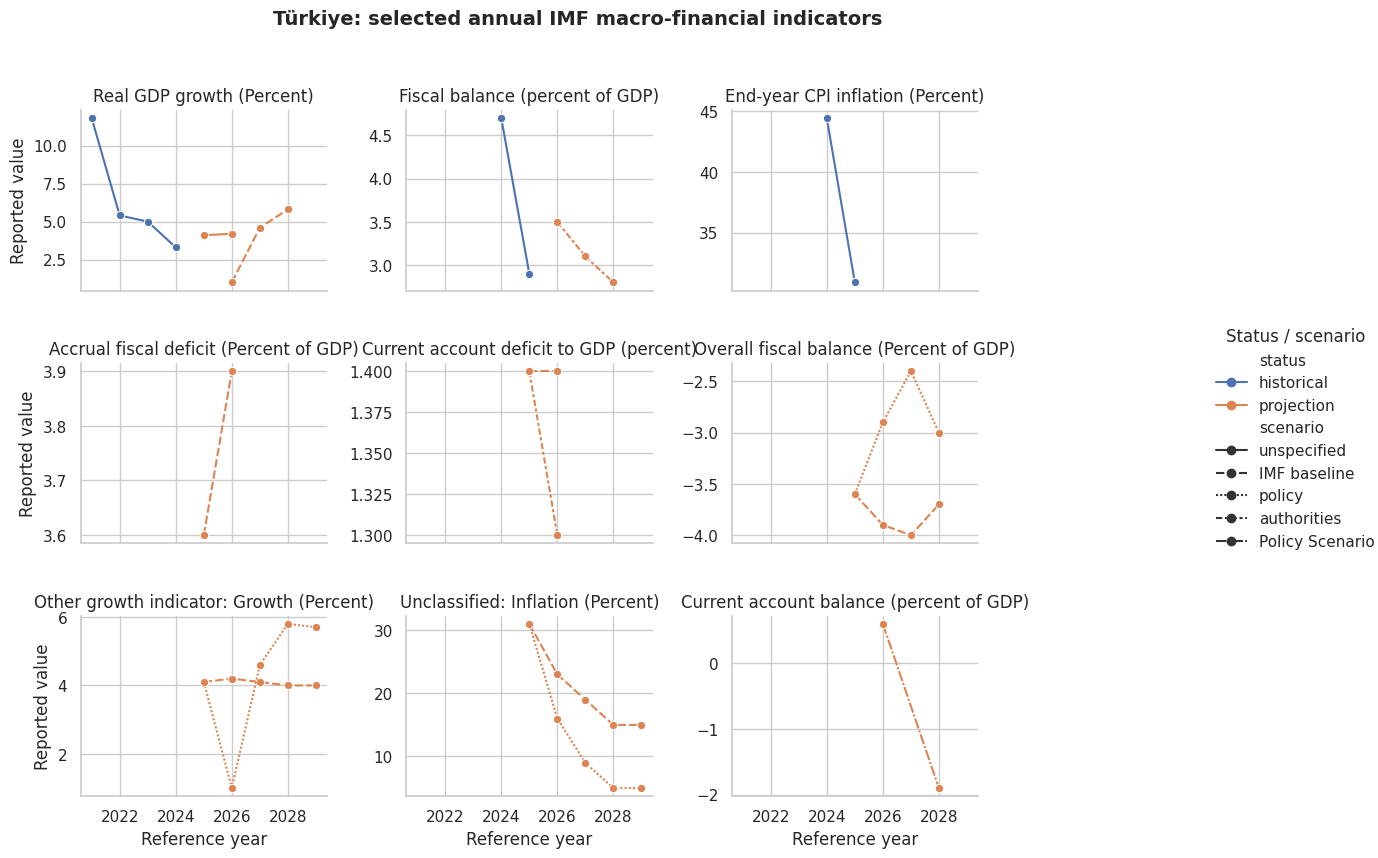

Faceted chart saved: /content/drive/MyDrive/24142515_Turkiye_IMF/outputs/figures/turkiye_macro_indicators_faceted_300dpi.png
Displayed facets: 9 | omitted: 6


In [28]:
# faceted chart: annual series only, with external legend and full audit retention.
facet_all=trend_df_chart.copy() if "trend_df_chart" in globals() and not trend_df_chart.empty else pd.DataFrame()
if not facet_all.empty:
    facet_all["year"]=pd.to_numeric(facet_all["year"],errors="coerce")
    facet_all["value"]=pd.to_numeric(facet_all["value"],errors="coerce")
    facet_all=facet_all.dropna(subset=["year","value"])
    facet_all["year"]=facet_all["year"].astype(int)
    facet_all=facet_all[
        facet_all["period_definition"].astype(str).str.lower().str.contains(
            "annual|end-year|end year|period-average",regex=True,na=False
        )
    ].copy()
    if not facet_all.empty:
        cols=["indicator","original_indicator","unit","period_definition","scenario","status"]
        facet_all["series_id"]=facet_all[cols].astype(str).agg(" | ".join,axis=1)
        facet_all["facet_label"]=facet_all["indicator"].astype(str)+" ("+facet_all["unit"].astype(str)+")"
        clean=[]
        for _,g in facet_all.groupby(["series_id","year"],dropna=False):
            vals=g["value"].dropna().unique()
            if len(vals)==1: clean.append(g.iloc[0].to_dict())
        facet_all=pd.DataFrame(clean)
        eligible=facet_all.groupby("series_id")["year"].nunique()
        eligible_ids=eligible[eligible>=2].index.tolist()
        eligible_data=facet_all[facet_all["series_id"].isin(eligible_ids)].copy()
        counts=eligible_data.groupby("facet_label")["series_id"].nunique().sort_values(ascending=False)
        chosen=counts.head(9).index.tolist()
        omitted=[x for x in counts.index if x not in chosen]
        facet_data=eligible_data[eligible_data["facet_label"].isin(chosen)].copy()
        facet_data.to_csv(OUT/"faceted_chart_data.csv",index=False,encoding="utf-8-sig")
        save_json("faceted_chart_selection.json",{
            "eligible_indicator_facets":int(len(counts)),
            "displayed_facets":chosen,
            "omitted_for_readability":omitted,
            "selection_rule":"Up to nine annual/end-year facets with at least two distinct years; point-in-time observations excluded."
        })
        if not facet_data.empty:
            g=sns.relplot(
                data=facet_data.sort_values("year"),x="year",y="value",
                hue="status",style="scenario",units="series_id",estimator=None,sort=True,
                col="facet_label",col_wrap=3,kind="line",marker="o",
                facet_kws={"sharey":False},height=2.8,aspect=1.2,legend="brief"
            )
            g.set_axis_labels("Reference year","Reported value")
            g.set_titles("{col_name}")
            if g._legend is not None:
                g._legend.set_bbox_to_anchor((1.02,.5))
                g._legend.set_loc("center left")
                g._legend.set_title("Status / scenario")
            g.fig.suptitle("Türkiye: selected annual IMF macro-financial indicators",y=1.02,fontsize=14,fontweight="bold")
            g.fig.subplots_adjust(top=.90,right=.84,wspace=.32,hspace=.40)
            facet_path=FIG/"turkiye_macro_indicators_faceted_300dpi.png"
            g.fig.savefig(facet_path,dpi=300,bbox_inches="tight")
            plt.show()
            print("Faceted chart saved:",facet_path)
            print("Displayed facets:",len(chosen),"| omitted:",len(omitted))
        else:
            print("No annual series with at least two distinct years; faceted chart skipped.")
    else:
        print("No annual/end-year observations available for faceted chart.")
else:
    print("No quote-supported trend observations available.")

## 17. Tidy data transformation, human verification and final dashboard

This section demonstrates a `pandas.melt` transformation of the extracted indicator matrix and provides a framework for comparison against a manually verified reference sample. It does not manufacture accuracy scores. The reference file is an annotation template; performance metrics are calculated only after a human reviewer verifies entries against the original IMF PDF.

The LLM judge remains a diagnostic instrument, not ground truth. Retrieval similarity is not treated as evidence of answer faithfulness.

Pandas melt transformation completed: (62, 57) wide -> (139, 6) long
Human gold-standard template: /content/drive/MyDrive/24142515_Turkiye_IMF/outputs/human_gold_standard_reference.csv
Important: populate only after manual verification against the source PDF; do not copy model output as ground truth.
No verified human gold-standard rows yet. Precision, recall and F1 are intentionally not reported.


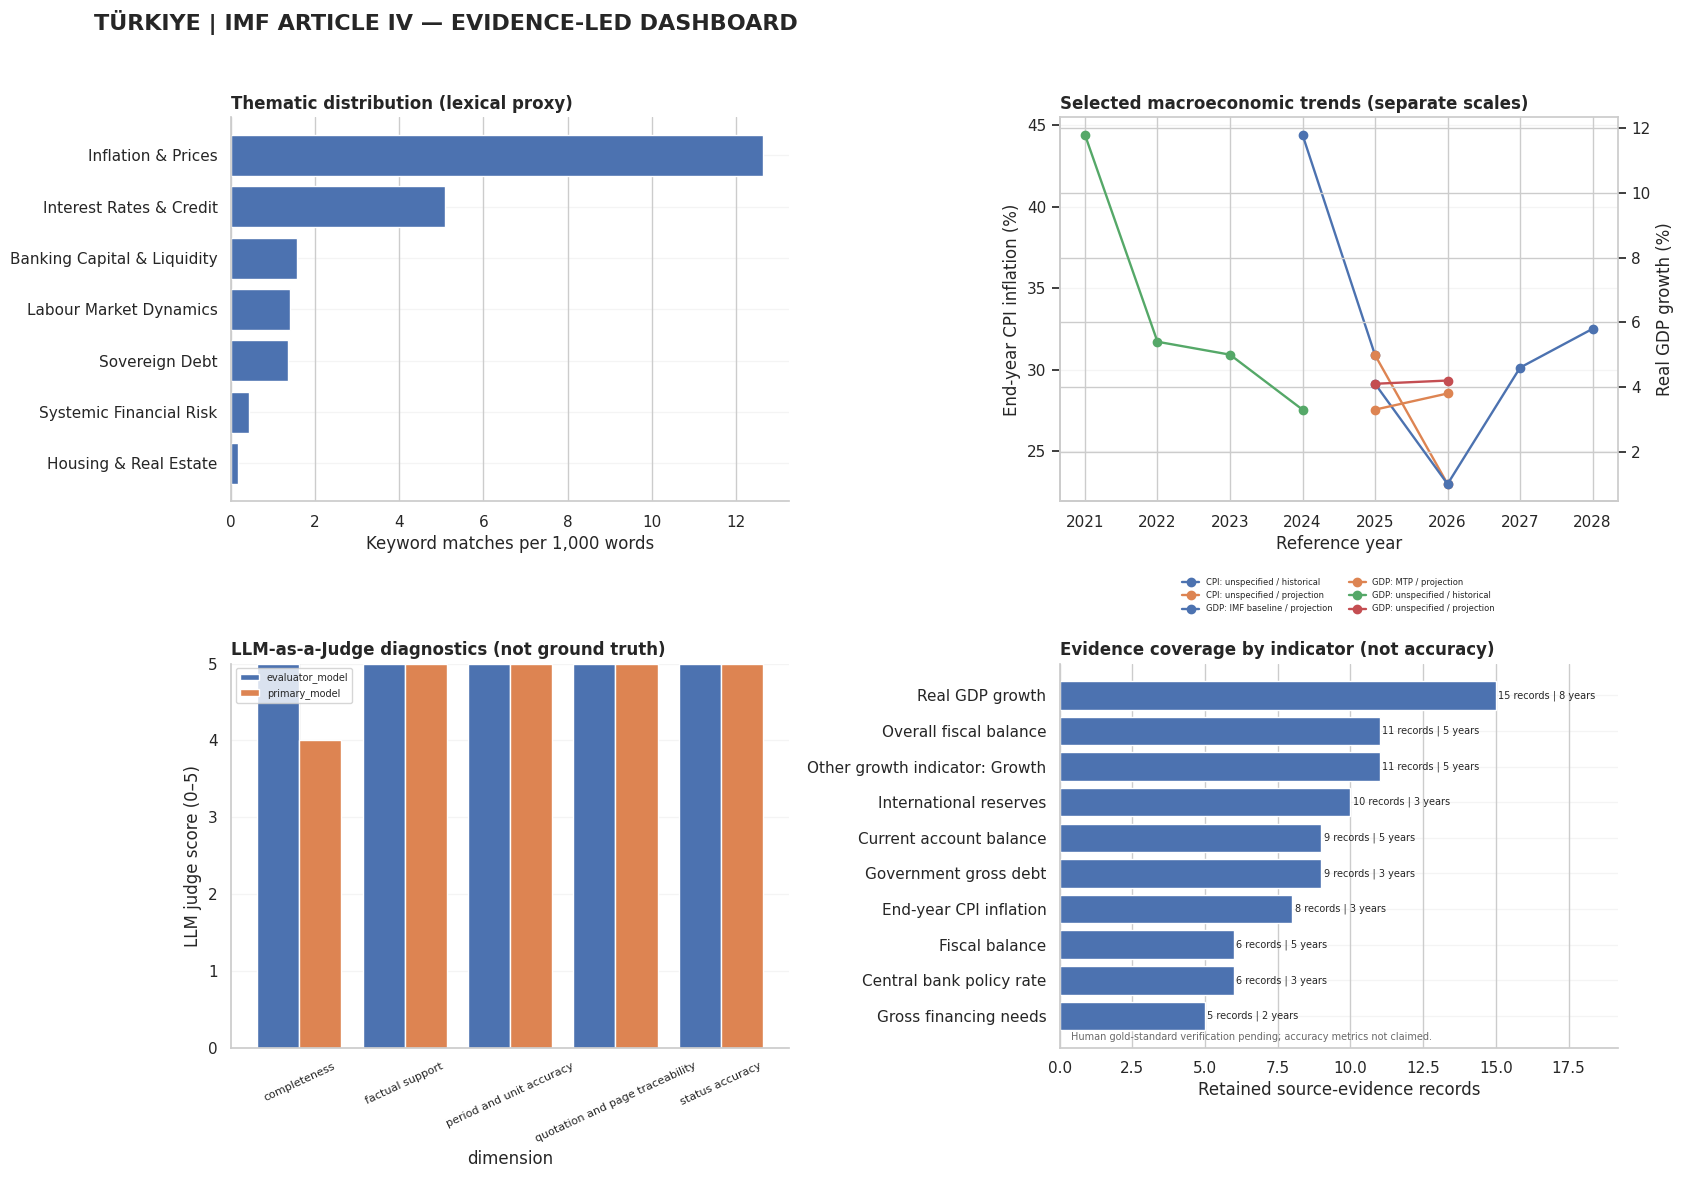

Dashboard saved: /content/drive/MyDrive/24142515_Turkiye_IMF/outputs/figures/turkiye_imf_dashboard_final_300dpi.png
RAG Triad evaluation status: completed
Evaluated retrieval methods: baseline, multi_query
Interpretation: LLM-judge scores are diagnostic and do not replace human source verification.


In [29]:
# Create a wide-to-long transformation using pandas.melt.
# Duplicate/conflicting observations are retained in an audit file and excluded from the plotted matrix.

trend_source_v8 = trend_df_chart.copy() if "trend_df_chart" in globals() and isinstance(trend_df_chart, pd.DataFrame) else pd.DataFrame()
required_trend_cols = {"indicator", "value", "year"}

if not trend_source_v8.empty and required_trend_cols.issubset(trend_source_v8.columns):
    trend_source_v8["year"] = pd.to_numeric(trend_source_v8["year"], errors="coerce")
    trend_source_v8["value"] = pd.to_numeric(trend_source_v8["value"], errors="coerce")
    trend_source_v8 = trend_source_v8.dropna(subset=["year", "value", "indicator"]).copy()
    trend_source_v8["year"] = trend_source_v8["year"].astype(int)

    # Preserve scenario, status and period definition so unlike observations are not combined.
    grouping_cols = [c for c in ["year", "scenario", "status", "period_definition"] if c in trend_source_v8.columns]
    if not grouping_cols:
        grouping_cols = ["year"]

    key_cols = grouping_cols + ["indicator"]
    duplicate_audit = (trend_source_v8.groupby(key_cols, dropna=False)["value"]
                       .agg(record_count="size", distinct_values="nunique")
                       .reset_index())
    duplicate_conflicts_v8 = duplicate_audit[duplicate_audit["distinct_values"] > 1].copy()
    duplicate_conflicts_v8.to_csv(OUT / "v8_wide_matrix_conflicts.csv", index=False, encoding="utf-8-sig")

    # Only unique indicator-period values enter the wide matrix. Exact duplicates are deduplicated.
    conflict_keys = set()
    for _, row in duplicate_conflicts_v8.iterrows():
        conflict_keys.add(tuple(str(row[c]) for c in key_cols))
    safe_rows = []
    for _, row in trend_source_v8.iterrows():
        key = tuple(str(row[c]) for c in key_cols)
        if key not in conflict_keys:
            safe_rows.append(row.to_dict())
    safe_trends_v8 = pd.DataFrame(safe_rows).drop_duplicates(subset=key_cols + ["value"])

    if not safe_trends_v8.empty:
        wide_indicators_v8 = safe_trends_v8.pivot(index=grouping_cols, columns="indicator", values="value").reset_index()
        wide_indicators_v8.columns.name = None
        value_columns_v8 = [c for c in wide_indicators_v8.columns if c not in grouping_cols]
        indicators_long_v8 = pd.melt(
            wide_indicators_v8,
            id_vars=grouping_cols,
            value_vars=value_columns_v8,
            var_name="indicator",
            value_name="value"
        ).dropna(subset=["value"])
        indicators_long_v8 = indicators_long_v8.sort_values(grouping_cols + ["indicator"]).reset_index(drop=True)
        wide_indicators_v8.to_csv(OUT / "indicator_matrix_wide_v8.csv", index=False, encoding="utf-8-sig")
        indicators_long_v8.to_csv(OUT / "indicator_matrix_long_v8.csv", index=False, encoding="utf-8-sig")
        print("Pandas melt transformation completed:", wide_indicators_v8.shape, "wide ->", indicators_long_v8.shape, "long")
    else:
        wide_indicators_v8 = pd.DataFrame()
        indicators_long_v8 = pd.DataFrame()
        print("No conflict-free observations were available for the wide-to-long matrix.")
else:
    wide_indicators_v8 = pd.DataFrame()
    indicators_long_v8 = pd.DataFrame()
    duplicate_conflicts_v8 = pd.DataFrame()
    print("Trend data unavailable or missing required fields; pd.melt output was not fabricated.")

# B. Create a human-verified gold-standard annotation template.
# Complete this CSV manually after checking the exact page and definition in the IMF PDF.
gold_path_v8 = OUT / "human_gold_standard_reference.csv"
gold_columns_v8 = [
    "indicator", "value", "unit", "reference_period", "scenario", "status",
    "PDF_page", "source_quote", "reviewer_verified"
]
if not gold_path_v8.exists():
    pd.DataFrame(columns=gold_columns_v8).to_csv(gold_path_v8, index=False, encoding="utf-8-sig")

print("Human gold-standard template:", gold_path_v8)
print("Important: populate only after manual verification against the source PDF; do not copy model output as ground truth.")

# C. Compare predictions with human labels only when the gold file contains verified rows.
gold_v8 = pd.read_csv(gold_path_v8)
if not gold_v8.empty and "reviewer_verified" in gold_v8.columns:
    gold_v8["reviewer_verified"] = gold_v8["reviewer_verified"].astype(str).str.strip().str.lower().isin(["true", "yes", "1", "verified"])
    gold_v8 = gold_v8[gold_v8["reviewer_verified"]].copy()

pred_v8 = trend_review_df.copy() if "trend_review_df" in globals() and isinstance(trend_review_df, pd.DataFrame) else pd.DataFrame()

if not gold_v8.empty and not pred_v8.empty:
    # Normalize field names conservatively; no inferred period or unit is inserted.
    pred_map = {
        "indicator": "indicator", "value": "value", "unit": "unit",
        "reference_period": "reference_period", "scenario": "scenario",
        "status": "status", "PDF_page": "PDF_page", "source_quote": "source_quote"
    }
    for target, source_col in [(k, v) for k, v in pred_map.items()]:
        if source_col not in pred_v8.columns:
            if target == "reference_period" and "period_definition" in pred_v8.columns:
                pred_v8[target] = pred_v8["period_definition"].astype(str)
            elif target in ["scenario", "status", "unit", "PDF_page", "source_quote", "indicator", "value"]:
                pred_v8[target] = "" if target != "value" else np.nan
    pred_v8["value"] = pd.to_numeric(pred_v8["value"], errors="coerce")
    gold_v8["value"] = pd.to_numeric(gold_v8["value"], errors="coerce")
    match_keys_v8 = ["indicator", "reference_period", "scenario", "status"]
    for df_v8 in [pred_v8, gold_v8]:
        for col in match_keys_v8:
            df_v8[col] = df_v8[col].fillna("").astype(str).str.strip().str.lower()
    pred_v8 = pred_v8.dropna(subset=["value"]).copy()
    gold_v8 = gold_v8.dropna(subset=["value"]).copy()
    comparison_v8 = gold_v8.merge(
        pred_v8[match_keys_v8 + ["value"]], on=match_keys_v8, how="outer",
        suffixes=("_gold", "_pred"), indicator=True
    )
    comparison_v8["numeric_match"] = (
        comparison_v8["_merge"].eq("both") &
        np.isclose(comparison_v8["value_gold"].fillna(np.inf), comparison_v8["value_pred"].fillna(-np.inf), atol=0.01, rtol=0)
    )
    tp_v8 = int(comparison_v8["numeric_match"].sum())
    gold_n_v8 = int(len(gold_v8))
    pred_n_v8 = int(len(pred_v8))
    precision_v8 = tp_v8 / pred_n_v8 if pred_n_v8 else np.nan
    recall_v8 = tp_v8 / gold_n_v8 if gold_n_v8 else np.nan
    f1_v8 = (2 * precision_v8 * recall_v8 / (precision_v8 + recall_v8)) if pd.notna(precision_v8) and pd.notna(recall_v8) and (precision_v8 + recall_v8) else 0.0
    comparison_v8.to_csv(OUT / "human_gold_standard_comparison_v8.csv", index=False, encoding="utf-8-sig")
    human_metrics_v8 = {
        "verified_gold_records": gold_n_v8, "prediction_records": pred_n_v8,
        "exact_record_matches_with_value_tolerance_0_01": tp_v8,
        "precision": precision_v8, "recall": recall_v8, "f1": f1_v8,
        "definition": "Record-level match on indicator, reference period, scenario and status; numerical tolerance 0.01. Human-labelled rows only."
    }
    save_json("human_gold_standard_metrics_v8.json", human_metrics_v8)
    print("Human-reference metrics calculated:", human_metrics_v8)
else:
    human_metrics_v8 = None
    print("No verified human gold-standard rows yet. Precision, recall and F1 are intentionally not reported.")

# D. Export a complete evidence-led four-panel dashboard.
# Judge scores are labelled as model diagnostics; they are not presented as factual accuracy.
fig_v8, ax_v8 = plt.subplots(2, 2, figsize=(17, 12))
fig_v8.patch.set_facecolor("white")
for a in ax_v8.flat:
    a.grid(axis="y", alpha=0.2)
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)

# Panel 1: seven-theme lexical density.
if "theme_df" in globals() and isinstance(theme_df, pd.DataFrame) and not theme_df.empty:
    t = theme_df.sort_values("matches_per_1000_words")
    ax_v8[0, 0].barh(t["theme"].astype(str), t["matches_per_1000_words"])
    ax_v8[0, 0].set_xlabel("Keyword matches per 1,000 words")
    ax_v8[0, 0].set_title("Thematic distribution (lexical proxy)", loc="left", weight="bold")
else:
    ax_v8[0, 0].text(.5, .5, "Theme output unavailable", ha="center", va="center", transform=ax_v8[0, 0].transAxes)
    ax_v8[0, 0].set_title("Thematic distribution", loc="left", weight="bold")

# Panel 2: selected annual/end-year series; preserve scenario and status distinctions.
if not indicators_long_v8.empty and "year" in indicators_long_v8.columns:
    annual_v8 = indicators_long_v8.copy()
    annual_v8["year"] = pd.to_numeric(annual_v8["year"], errors="coerce")
    annual_v8 = annual_v8.dropna(subset=["year", "value"])
    if "period_definition" in annual_v8.columns:
        annual_v8 = annual_v8[annual_v8["period_definition"].astype(str).str.lower().str.contains("annual|end-year|end year|period-average", regex=True, na=False)]
    chosen_v8 = [x for x in ["End-year CPI inflation", "Real GDP growth"] if x in annual_v8["indicator"].astype(str).unique()]
    plotted_v8 = False
    ax_gdp_v8 = ax_v8[0, 1].twinx()
    for metric in chosen_v8:
        sub = annual_v8[annual_v8["indicator"].astype(str) == metric]
        target_ax = ax_v8[0, 1] if metric == "End-year CPI inflation" else ax_gdp_v8
        if not sub.empty:
            group_cols = [c for c in ["scenario", "status"] if c in sub.columns]
            grouped = sub.groupby(group_cols, dropna=False) if group_cols else [("series", sub)]
            for group_key, grp in grouped:
                grp = grp.sort_values("year")
                # Keep only one unambiguous value per year; conflicts remain in the audit CSV.
                unique_rows = []
                for year_value, year_group in grp.groupby("year"):
                    vals = pd.to_numeric(year_group["value"], errors="coerce").dropna().unique()
                    if len(vals) == 1:
                        unique_rows.append((int(year_value), float(vals[0])))
                if len(unique_rows) >= 2:
                    xx, yy = zip(*sorted(unique_rows))
                    # Shorten legend labels while retaining scenario and status distinctions.
                    if isinstance(group_key, tuple):
                        group_parts = [str(x) for x in group_key if str(x) not in ("", "nan", "None")]
                    else:
                        group_parts = [str(group_key)]
                    group_label = " / ".join(group_parts)
                    short_metric = "CPI" if metric == "End-year CPI inflation" else "GDP"
                    line_label = f"{short_metric}: {group_label}" if group_label else short_metric
                    target_ax.plot(xx, yy, marker="o", linewidth=1.7, label=line_label)
                    plotted_v8 = True
    if plotted_v8:
        ax_v8[0, 1].set_xlabel("Reference year")
        ax_v8[0, 1].set_ylabel("End-year CPI inflation (%)")
        ax_gdp_v8.set_ylabel("Real GDP growth (%)")
        h1, l1 = ax_v8[0, 1].get_legend_handles_labels()
        h2, l2 = ax_gdp_v8.get_legend_handles_labels()
        if h1 or h2:
            ax_v8[0, 1].legend(h1 + h2, l1 + l2, fontsize=6, loc="upper center",
                               bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
    else:
        ax_v8[0, 1].text(.5, .5, "No comparable multi-year series", ha="center", va="center", transform=ax_v8[0, 1].transAxes)
    ax_v8[0, 1].set_title("Selected macroeconomic trends (separate scales)", loc="left", weight="bold")
else:
    ax_v8[0, 1].text(.5, .5, "No verified long-format trend data", ha="center", va="center", transform=ax_v8[0, 1].transAxes)
    ax_v8[0, 1].set_title("Selected macroeconomic trends", loc="left", weight="bold")

# Panel 3: controlled model judge scores, explicitly not ground-truth accuracy.
judge_obj_v8 = globals().get("benchmark_judgement", {})
score_rows_v8 = []
if isinstance(judge_obj_v8, dict):
    for model_label, scores in judge_obj_v8.items():
        if isinstance(scores, dict):
            for metric in ["factual_support", "period_and_unit_accuracy", "status_accuracy", "quotation_and_page_traceability", "completeness"]:
                if isinstance(scores.get(metric), (int, float)):
                    score_rows_v8.append({"model": model_label, "dimension": metric.replace("_", " "), "score": scores[metric]})
if score_rows_v8:
    sj = pd.DataFrame(score_rows_v8)
    pivot_j = sj.pivot(index="dimension", columns="model", values="score")
    pivot_j.plot(kind="bar", ax=ax_v8[1, 0], ylim=(0, 5), width=.8)
    ax_v8[1, 0].set_ylabel("LLM judge score (0–5)")
    ax_v8[1, 0].tick_params(axis="x", rotation=25, labelsize=8)
    ax_v8[1, 0].legend(fontsize=7)
else:
    ax_v8[1, 0].text(.5, .5, "No comparable judge scores available", ha="center", va="center", transform=ax_v8[1, 0].transAxes)
ax_v8[1, 0].set_title("LLM-as-a-Judge diagnostics (not ground truth)", loc="left", weight="bold")

# Panel 4: actual source-evidence coverage by indicator.
# This is a coverage plot, NOT an accuracy score. Human precision/recall/F1
# remain separately reported only after manual PDF annotation is completed.
coverage_source_v8 = trend_source_v8.copy() if isinstance(trend_source_v8, pd.DataFrame) else pd.DataFrame()
if not coverage_source_v8.empty and "indicator" in coverage_source_v8.columns:
    coverage_source_v8["indicator"] = coverage_source_v8["indicator"].astype(str)
    coverage_source_v8 = coverage_source_v8[
        ~coverage_source_v8["indicator"].str.lower().str.startswith("unclassified:")
    ].copy()
    if not coverage_source_v8.empty:
        coverage_v8 = (coverage_source_v8.groupby("indicator", dropna=False)
                       .agg(evidence_records=("value", "count"),
                            distinct_years=("year", "nunique"))
                       .sort_values(["evidence_records", "distinct_years"], ascending=True)
                       .tail(10))
        bars_v8 = ax_v8[1, 1].barh(coverage_v8.index.astype(str), coverage_v8["evidence_records"])
        ax_v8[1, 1].set_xlabel("Retained source-evidence records")
        ax_v8[1, 1].set_ylabel("")
        ax_v8[1, 1].set_title("Evidence coverage by indicator (not accuracy)", loc="left", weight="bold")
        for bar_v8, (_, row_v8) in zip(bars_v8, coverage_v8.iterrows()):
            ax_v8[1, 1].text(bar_v8.get_width() + 0.08, bar_v8.get_y() + bar_v8.get_height()/2,
                             f"{int(row_v8['evidence_records'])} records | {int(row_v8['distinct_years'])} years",
                             va="center", fontsize=7)
        ax_v8[1, 1].margins(x=0.28)
    else:
        ax_v8[1, 1].text(.5, .5, "No classified indicator evidence available", ha="center", va="center", transform=ax_v8[1, 1].transAxes)
        ax_v8[1, 1].set_title("Evidence coverage by indicator", loc="left", weight="bold")
else:
    ax_v8[1, 1].text(.5, .5, "Trend evidence unavailable", ha="center", va="center", transform=ax_v8[1, 1].transAxes)
    ax_v8[1, 1].set_title("Evidence coverage by indicator", loc="left", weight="bold")

# Human verification status is retained in the accompanying CSV/JSON audit files.
if not human_metrics_v8:
    ax_v8[1, 1].text(.02, .02, "Human gold-standard verification pending; accuracy metrics not claimed.",
                     transform=ax_v8[1, 1].transAxes, fontsize=7, color="dimgray")

fig_v8.suptitle("TÜRKIYE | IMF ARTICLE IV — EVIDENCE-LED DASHBOARD", fontsize=16, weight="bold", x=.06, ha="left")
fig_v8.tight_layout(rect=[0, 0, 1, .96])
dashboard_v8_path = FIG / "turkiye_imf_dashboard_final_300dpi.png"
fig_v8.savefig(dashboard_v8_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print("Dashboard saved:", dashboard_v8_path)

# Report the RAG Triad result produced in the preceding evaluation section.
# Do not launch a second judge call here or describe a completed evaluation as opt-in.
rag_results_final = globals().get("rag_triad_results", {})
rag_errors_final = globals().get("rag_triad_errors", {})
if isinstance(rag_results_final, dict) and rag_results_final:
    print("RAG Triad evaluation status: completed")
    print("Evaluated retrieval methods:", ", ".join(rag_results_final.keys()))
else:
    print("RAG Triad evaluation status: not completed")
    if rag_errors_final:
        print("Recorded RAG Triad errors:", rag_errors_final)
print("Interpretation: LLM-judge scores are diagnostic and do not replace human source verification.")

## 18. Human verification, run manifest and output archive

### Manual verification requirements

The six core-indicator values are populated using extraction evidence and official-source audit anchors. This is not the same as student verification. In particular, check the end-year CPI definition, the exact 35.4 percent IMF baseline policy-rate projection for 2026 Q1 in Text Table 3 (the Annex narrative rounds this to 36 percent), and the Common Tier 1 ratio (CT1R) label before submission.

- Annotate a representative sample in `human_gold_standard_reference.csv` using the original IMF PDF.
- Record the exact indicator definition, value, unit, reference period, scenario, status, PDF page and a short source quotation.
- Set `reviewer_verified` to `yes` only after checking the source page.
- Report precision, recall and F1 only when verified reference rows are available; state the matching rule and tolerance.
- Review the conflict audit files. Conflicting same-period observations must not be silently averaged or selected.
- Treat automated judge scores as diagnostics and human source verification as the reference standard.

In [30]:
# Human verification log, reproducibility manifest and output archive.

verification_rows = []
verification_fields = [
    ("gdp_growth_forecast_pct", "GDP growth forecast"),
    ("headline_inflation_rate_pct", "Headline CPI inflation"),
    ("central_bank_policy_rate_pct", "Central bank policy rate"),
    ("non_performing_loan_ratio", "NPL ratio"),
    ("unemployment_rate_pct", "Unemployment rate"),
    ("tier_1_capital_ratio", "Tier 1 capital ratio")
]
for field, label in verification_fields:
    provenance = core_indicator_provenance.get(field, {}) if "core_indicator_provenance" in globals() else {}
    evidence_page = provenance.get("PDF_page", "")
    verification_rows.append([
        label,
        evidence_page,
        "PENDING — verify value, definition, period, unit and quotation against the source PDF",
        provenance.get("source_quote", "")
    ])

# Additional trend indicators selected for manual source review.
for label in [
    "Government gross debt",
    "Current account balance",
    "Private credit growth",
    "Primary fiscal balance",
    "Overall fiscal balance"
]:
    verification_rows.append([
        label, "",
        "PENDING — select representative observation and verify value, definition, period and quotation against the source PDF",
        ""
    ])

verification = pd.DataFrame(
    verification_rows,
    columns=["Indicator", "Evidence PDF page (not yet verified)", "Human verdict", "Source quotation / correction / explanation"]
)
verification.to_csv(OUT / "human_verification_log.csv", index=False, encoding="utf-8-sig")

# Consolidate unresolved trend records into one transparent manual-review queue.
review_queue_frames = []
for review_label, review_frame in [
    ("potential_conflict", globals().get("trend_conflicts_df")),
    ("unsupported_quote", globals().get("trend_unsupported_df")),
    ("unclassified_indicator", globals().get("trend_suspicious_df"))
]:
    if isinstance(review_frame, pd.DataFrame) and not review_frame.empty:
        queued = review_frame.copy()
        queued.insert(0, "review_category", review_label)
        review_queue_frames.append(queued)
if review_queue_frames:
    trend_manual_review_queue = pd.concat(review_queue_frames, ignore_index=True, sort=False)
else:
    trend_manual_review_queue = pd.DataFrame(columns=["review_category", "indicator", "value", "year", "PDF_page", "source_quote"])
trend_manual_review_queue.to_csv(OUT / "trend_manual_review_queue.csv", index=False, encoding="utf-8-sig")
print("Trend manual-review queue:", len(trend_manual_review_queue), "records; no conflicts were auto-resolved.")

model_log_path = OUT / "gemini_model_log.jsonl"
model_log = []
if model_log_path.exists():
    for line in model_log_path.read_text(encoding="utf-8").splitlines():
        try:
            model_log.append(json.loads(line))
        except json.JSONDecodeError:
            pass

manifest = {
    "student_id": "24142515",
    "country": "Türkiye",
    "report": "IMF Country Report No. 26/043",
    "source_pdf": PDF_URL,
    "source_pdf_sha256": pdf_hash,
    "pdf_pages": len(reader.pages),
    "nonempty_text_pages": sum(bool(p["text"]) for p in pages),
    "chunks": len(chunks),
    "chunk_config": chunk_config,
    "tokenizer_note": "cl100k_base is an approximate proxy, not Gemini's internal tokenizer.",
    "embedding_model": EMBED_MODEL,
    "retrieval_backend": BACKEND,
    "primary_model": GEMINI_MODEL,
    "fallback_model": FALLBACK_MODEL,
    "judge_model": JUDGE_MODEL,
    "model_requests_logged": len(model_log),
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "human_verification_required": True,
    "student_human_verification_completed": False,
    "trend_manual_review_queue_count": int(len(trend_manual_review_queue)),
    "pd_melt_output_rows": int(len(indicators_long_v8)) if "indicators_long_v8" in globals() else 0,
    "human_gold_metrics_available": bool(globals().get("human_metrics_v8")),
     "notebook_version": "final-submission-v4",
    "indicator_extraction_prompt_version": "indicator-extraction-v6 (period-aware selection; exact baseline policy-rate table preference and source-audit fallback)",
    "trend_extraction_prompt_version": "annual-trends-v6 (retained cached baseline; source audit and final visualisation)",
    "trend_observation_count": int(len(trend_review_df)) if "trend_review_df" in globals() else 0,
    "trend_unclassified_count": int(len(trend_suspicious_df)) if "trend_suspicious_df" in globals() else 0,
    "trend_conflict_count": int(len(trend_conflicts_df)) if "trend_conflicts_df" in globals() else 0,
    "rag_triad_judge_enabled": bool(globals().get("RUN_RAG_TRIAD_JUDGE", False) or globals().get("RUN_RAG_TRIAD_JUDGE_V7", False)),
    "unsupported_trend_evidence_count": int(len(trend_unsupported_df)) if "trend_unsupported_df" in globals() else None,
    "sequential_change_count": int(len(trend_sequences_df)) if "trend_sequences_df" in globals() else None
}
save_json("run_manifest.json", manifest)

run_status = {
    "pdf_pages": len(reader.pages),
    "chunks": len(chunks),
    "theme_categories": len(THEMES),
    "numerical_evidence_records": len(indicators.get("evidence", [])),
    "qualitative_strengths": len(qualitative_final.get("strengths", [])),
    "qualitative_vulnerabilities": len(qualitative_final.get("vulnerabilities", [])),
    "trend_series": len(trend_result.get("series", [])),
    "trend_conflict_records": len(trend_conflicts_df),
    "core_indicator_schema_validation": schema_check if "schema_check" in globals() else "not_run",
    "human_verification_status": "pending_manual_source_checks",
    "trend_manual_review_queue": str(OUT / "trend_manual_review_queue.csv"),
     "dashboard": str(FIG / "turkiye_imf_dashboard_final_300dpi.png") if (FIG / "turkiye_imf_dashboard_final_300dpi.png").exists() else "not_generated",
    "faceted_chart": str(FIG / "turkiye_macro_indicators_faceted_300dpi.png"),
    "manual_verification_rows": len(verification),
    "note": "Successful execution and structural checks do not replace manual source verification. Human accuracy metrics are calculated only after a manually verified gold-standard file is supplied."
}
save_json("pipeline_run_status.json", run_status)

archive_path = shutil.make_archive(str(BASE / "turkiye_imf_outputs"), "zip", root_dir=OUT)
display(pd.DataFrame([{"check": key, "result": value} for key, value in run_status.items()]))
print("Output archive:", archive_path)

Trend manual-review queue: 82 records; no conflicts were auto-resolved.


,check,result
0,pdf_pages,115
1,chunks,241
2,theme_categories,7
3,numerical_evidence_records,59
4,qualitative_strengths,7
5,qualitative_vulnerabilities,7
6,trend_series,120
7,trend_conflict_records,18
8,core_indicator_schema_validation,"{'all_required_keys_present': True, 'country_n..."
9,human_verification_status,pending_manual_source_checks


Output archive: /content/drive/MyDrive/24142515_Turkiye_IMF/turkiye_imf_outputs.zip


## 19. Final quality-assurance and submission checklist

### Technical execution
- [ ] Run every cell from a fresh Colab runtime in sequence.
- [ ] Confirm the official IMF PDF identity, page count and SHA-256 hash.
- [ ] Confirm API secrets are stored in Colab Secrets and are not printed or committed.
- [ ] Confirm cached extraction, local embeddings, FAISS retrieval and all four dashboard panels complete.

### Evidence and analytical validity
- [ ] Review all six core-indicator values against the locally downloaded official IMF PDF and confirm page numbering.
- [ ] Preserve the definitions and periods: end-year CPI (not period-average CPI), baseline policy rate (2026Q1), NPLs/gross loans (2025Q2), CT1R (2025Q2).
- [ ] Mark `student_human_verified=yes` only after personally checking the source page and quotation.
- [ ] Review trend conflict and unsupported-quotation audit files; do not silently average or combine unlike scenarios.
- [ ] Treat RAG Triad and LLM-as-a-Judge scores as diagnostics, not independent ground truth.
- [ ] Do not report human precision, recall or F1 until the reference file contains manually verified labels.

### Submission
- [ ] Export the final JSON, CSV, dashboard PNG files and run manifest.
- [ ] Inspect the final output ZIP and confirm all report figures match the outputs.
- [ ] Prepare the separate 5–6-page PDF report with methodology, actual results, critical discussion, limitations and references.
- [ ] Share the executed Colab notebook with access for the marker.
- [ ] Include a README and an appropriate open-source licence if submitting through GitHub.

The official-source audit values are provided to support review. They do not remove the student's responsibility to check the source PDF and document human oversight.